In [1]:
import warnings
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from tqdm import tqdm

import matplotlib as mpl
import matplotlib.ticker as ticker
from matplotlib.ticker import MaxNLocator
from dateutil import parser

import matplotlib.cm as cm
from matplotlib.ticker import ScalarFormatter

import plotly.graph_objects as go
from plotly.subplots import make_subplots

warnings.filterwarnings('ignore') # Suppress all warnings (use with caution)

In [2]:
# Global configuration for plot titles and labels
mpl.rcParams['figure.titlesize'] = 18         # type: ignore # Main figure title size
mpl.rcParams['axes.titlesize'] = 16           # type: ignore # Axis title size
mpl.rcParams['axes.titleweight'] = 'bold'     # type: ignore # Axis title weight
mpl.rcParams['axes.labelsize'] = 14           # type: ignore # Axis label size
mpl.rcParams['axes.labelweight'] = 'normal'   # type: ignore # Axis label weight

Config3

In [3]:
# file = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Config3\ELPI+\RIB-PS\RIB-PS.dat' # RIB-PS_ELPI
# file_air_speed = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Config3\Speed\RIB-PS\2025-12-10-15-07-13.xlsx' # RIB-PS_air_speed
# file_HR_T = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Config3\T_HR\RIB-PS\file06.xlsx' # RIB-PS_HR_T

Config4

###### Speed and HR are a concatenated files

In [4]:
# file = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Config4\ELPI+\RIB-PS\RIB-PS.dat' # RIB-PS_ELPI .dat
# file_air_speed = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Config4\Speed\RIB-PS\concatenated_file.xlsx' # RIB-PS_air_speed .xlsx
# file_HR_T = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Config4\T-HR\RIB-PS\concatenated_file.xlsx' # RIB-PS_HR_T .xlsx 

Config5

###### Speed and HR are a concatenated files

In [5]:
# file = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Config5\ELPI+\RIB-PS\RIB-PS.dat' # RIB-PS_ELPI .dat
# file_air_speed = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Config5\Speed\RIB-PS\concatenated_file.xlsx' # RIB-PS_air_speed .xlsx
# file_HR_T = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Config5\T-HR\RIB-PS\concatenated_file.xlsx' # RIB-PS_HR_T .xlsx

Config6

In [6]:
file = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Config6\ELPI+\RIB-PS\RIB-PS.dat' # RIB-PS_ELPI .dat
file_air_speed = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Config6\Speed\RIB-PS\2026-02-23-15-56-32.xlsx' # RIB-PS_air_speed .xlsx
file_HR_T = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Config6\T-HR\RIB-PS\RIB-PS.xlsx' # RIB-PS_HR_T .xlsx

Config7

In [7]:
# file = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Config7\ELPI+\RIB-PS\RIB-PS.dat' # RIB-PS_ELPI .dat
# file_air_speed = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Config7\Speed\RIB-PS\2026-02-24-15-16-38.xlsx' # RIB-PS_air_speed .xlsx
# file_HR_T = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Config7\T-HR\RIB-PS\RIB-PS.xlsx' # RIB-PS_HR_T .xlsx

Titles

In [8]:
# n = "Config3_RIB-PS"  
# n = "Config4_RIB-PS"  
# n = "Config5_RIB-PS" 
n = "Config6_RIB-PS"  
# n = "Config7_RIB-PS" 

Start_time & End_time

In [9]:
# # Config3
# Start_datetime = '2025-12-10 11:35:00'
# End_datetime = '2025-12-10 15:07:00'

# #Config4
# Start_datetime = '2025-12-11 11:27:00'
# End_datetime = '2025-12-11 15:01:00'

# # Config5
# Start_datetime = '2025-12-12 11:19:16'
# End_datetime = '2025-12-12 14:55:00'

# # Config6
Start_datetime = '2026-02-23 11:55:00'
End_datetime = '2026-02-23 15:55:18'

# # Config7
# Start_datetime = '2026-02-24 11:08:00'
# End_datetime = '2026-02-24 15:15:37'

ELPI data

In [10]:
speed_correction = 210 # Channel1: Speed: Volt --> RPM
pressure_correction = 1 # Channel2: Pressure: Volt --> bar
temperature_correction = 100 # Channel3: Temperature: Volt --> °C

Physical Data

In [11]:
# Read channel info from the file header
with open(file, 'r') as f: # type: ignore
    content=f.read().split('\n')
 # Extract channel info from line 13
    physical_channels = np.array(content[12].split('=')[-1].split(',')).astype(float) # type: ignore

# Read physical data from CSV, select columns 0 and 2-15
physical_data = pd.read_csv(file,sep=',',header=36, usecols=np.append([0],np.arange(2,16,1)), index_col=0)

# Assign channel names (skip first beacause we have 15 physical_channels and 14 physical data)
physical_data.columns=physical_channels[1:]
physical_data.dropna(inplace=True)

# Convert index to datetime
physical_data.index = pd.to_datetime(physical_data.index, errors='coerce')
physical_data.index.names =['DateTime']
physical_data.reset_index(drop=False, inplace=True)

# Calculate elapsed time in seconds
physical_data['Time [s]'] = (physical_data['DateTime'] - physical_data['DateTime'].iloc[0]).dt.total_seconds()

All needed channels: Speed, Pressure and Temperature

In [12]:
columns = np.append([0],np.arange(22,25,1)) # Selecting of: Channel1: Speed Channel2:Pressure Channel3: Temperature
columns = np.append(columns,[36]) # Selecting of: Total number concentration
columns = np.append(columns,np.arange(38,538,1)) # Selecting of: Normalized number concentration from 1 to 500 : columns number 38 to 537

Data

In [13]:
# Load data
data = pd.read_csv(file, sep=',', header=36, usecols=columns, index_col=0)
data.dropna(inplace=True)

# Convert index to datetime
data.index = pd.to_datetime(data.index, format='%Y/%m/%d %H:%M:%S') # for 1Hz frequency
data.index.names =['DateTime']
data.reset_index(drop=False, inplace=True)

# Rename columns for clarity
data.rename(columns={data.columns[1]:'Speed', data.columns[2]:'Pressure', data.columns[3]:'Temperature'}, inplace=True) 

# Apply correction factors
data['Speed'] = data['Speed']*speed_correction 
data['Pressure'] = data['Pressure']*pressure_correction 
data['Temperature'] = data['Temperature']*temperature_correction 

# Calculate elapsed time
data['Time [s]'] = (data['DateTime'] - data['DateTime'].iloc[0]).dt.total_seconds()

Air outlet speed data

In [14]:
# Read the Excel file using the openpyxl engine
data_air_speed = pd.read_excel(file_air_speed, engine='openpyxl')

# Convert the first column to datetime
first_col = data_air_speed.columns[0]
data_air_speed[first_col] = pd.to_datetime(data_air_speed[first_col], errors='coerce')

# Find the first row where time is NaN (empty or invalid)
first_nan = data_air_speed[first_col].isna().idxmax() if data_air_speed[first_col].isna().any() else len(data_air_speed)

# Keep only rows before the first NaN timestamp
data_air_speed = data_air_speed.iloc[:first_nan].copy()

# Reset index
data_air_speed.reset_index(drop=True, inplace=True)

# Select only columns that don't start with 'Unnamed' and keep the first 3 columns
columns_to_keep = [col for col in data_air_speed.columns if 'Unnamed' not in col][:3]
data_air_speed = data_air_speed[columns_to_keep]

# Rename the columns properly
if len(columns_to_keep) >= 3:
    data_air_speed.columns = ['Date/Heure', 'Air_speed', 'Débit volumétrique [m³/h]']

# Remove any rows where essential data is missing
data_air_speed.dropna(subset=['Air_speed', 'Débit volumétrique [m³/h]'], inplace=True)

# Reset index again
data_air_speed.reset_index(drop=True, inplace=True)

# Calculate elapsed time
start_time = data_air_speed['Date/Heure'].iloc[0]
data_air_speed['Time [s]'] = (data_air_speed['Date/Heure'] - start_time).dt.total_seconds()

# Display the cleaned dataframe
# data_air_speed

Air outlet T-HR data

In [15]:
# Read the Excel file without headers
data_air_HR_T = pd.read_excel(file_HR_T, engine='openpyxl', header=None) # type: ignore

# Drop rows with missing values
data_air_HR_T.dropna(inplace=True)

# Assign correct column names based on your screenshot
data_air_HR_T.columns = ['Date', 'Time', 'HR', 'Temperature', 'Extra1', 'Extra2']

# Drop columns E and F (Extra1 and Extra2)
data_air_HR_T.drop(columns=['Extra1', 'Extra2'], inplace=True)

# Combine Date and Time into a single datetime column
data_air_HR_T['Datetime'] = pd.to_datetime(
    data_air_HR_T['Date'].astype(str) + ' ' + data_air_HR_T['Time'].astype(str),
    errors='coerce'
)

# Drop original Date and Time columns to avoid duplication
data_air_HR_T.drop(columns=['Date', 'Time'], inplace=True)

# Ensure HR and Temperature are numeric
data_air_HR_T['HR'] = pd.to_numeric(data_air_HR_T['HR'], errors='coerce')
data_air_HR_T['Temperature'] = pd.to_numeric(data_air_HR_T['Temperature'], errors='coerce')

# Calculate elapsed time in seconds from the first timestamp
data_air_HR_T['Time [s]'] = (data_air_HR_T['Datetime'] - data_air_HR_T['Datetime'].iloc[0]).dt.total_seconds()

# Reset index
data_air_HR_T.reset_index(drop=True, inplace=True)

# print(data_air_HR_T.head())

Plot: Raw data in current (fA) vs time and Dp

In [16]:
# fig, (ax1, ax2) = plt.subplots(ncols=2, gridspec_kw={'width_ratios':(1,0.5), 'wspace':0.1})
# fig.set_size_inches(w=30, h=8)

# fig.suptitle(f"{n}")

# ax1.plot(physical_data['Time [s]'], physical_data[physical_data.columns[1:-1]].sum(axis=1))
# ax1.set_ylabel('Total instantaneous current [fA]')
# ax1.set_xlabel('Time [s]')
# ax1.grid(alpha=0.2)
# ax1.set_xlim(left=0)
# ax1.set_ylim(bottom=0)
# ax1.margins(x=0)
# # ax1.set_xlim(200,2000)


# # Pour l'axe y de ax1 en notation scientifique
# ax1.yaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
# ax1.ticklabel_format(axis='y', style='sci', scilimits=(0,0))

# ax2.bar(physical_data.columns[1:-1].astype(float)*1000, height= physical_data[physical_data.columns[1:-1]].sum(axis=0),width=1000* physical_data.columns[1:-1].astype(float)/5 )
# ax2.set_xscale('log')
# ax2.set_xmargin(0)
# ax2.grid(alpha=0.2)
# ax2.set_ylabel('Instantaneous current [fA]')
# ax2.set_xlabel('Particles Dia. [nm]')
# ax2.set_yscale('log')
# # Pour l'axe y de ax2 en notation scientifique
# ax2.yaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
# ax2.ticklabel_format(axis='y', style='sci', scilimits=(0,0))

# # Ajout des étiquettes de diamètre sur chaque barre
# for bar, diameter in zip(ax2.patches, physical_data.columns[1:-1].astype(float) * 1000):
#     height = bar.get_height()
#     if height > 0:  # éviter log(0)
#         ax2.text(
#             bar.get_x() + bar.get_width() / 2,
#             height * 1.1,
#             f"{diameter:.0f} nm",
#             ha='center',
#             va='bottom',
#             fontsize=10,
#             rotation=90
#         )

Plot: Total number concentration [#/cm3] vs time

In [17]:
# fig, (ax1, ax2)= plt.subplots(ncols=1,nrows=2, sharex=True, gridspec_kw={'height_ratios':(1,0.5), 'hspace':0.1})
# fig.set_size_inches(w=25, h=15)

# fig.suptitle(f"{n}", y=0.9, fontweight='bold')

# # Définir les limites communes de l'axe X
# time_min = 0
# time_max = 13000


# ax1.yaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
# ax1.ticklabel_format(style='sci', axis='y', scilimits=(0, 0))

# ax1.plot(data['Time [s]'], data[data.columns[4]])
# ax1.vlines(x=40, ymin=ax1.get_ylim()[0], ymax=ax1.get_ylim()[1], color='gray', linestyle='--')
# ax1.set_ylabel('Number concentration [#/cm3]')
# ax1.set_xlabel('Time [s]')
# ax1.grid(alpha=0.2)
# ax1.margins(x=0)
# # ax1.set_yscale('log')
# ax1.set_ylim(bottom=1E3, top=3E4)
# # ax1.set_xlim(left=0)

# ax2_1 = ax2.twinx()
# ax2_2 = ax2.twinx()

# ax2.set_xlim(time_min, time_max)
# ax2.plot(data['Time [s]'], data['Speed']*(80/500), color='tab:blue') # RPM -> km/h
# ax2.vlines(x=40, ymin=ax2.get_ylim()[0], ymax=ax2.get_ylim()[1], color='gray', linestyle='--')
# ax2_1.plot(data['Time [s]'], data['Pressure'], color='tab:green')
# ax2_2.plot(data['Time [s]'], data['Temperature'], color='tab:red')
# ax2.margins(x=0)
# ax2.set_ylim(bottom=0)
# ax2_2.spines['right'].set_position(('outward', 60))  # déplace le troisième axe y vers l'extérieur
# ax2_2.set_ylabel('Temperature [°C]', color='tab:red')
# ax2_1.set_ylabel('Pressure [bar]', color='tab:green')
# ax2.set_ylabel('Speed [km/h]', color='tab:blue')
# ax2.set_xlabel('Time [s]')
# ax2.grid(alpha=0.2)
# ax1.set_ylim(1E3,1E7)
# ax1.set_yscale('log')

# # y1=183
# # y2=261
# # y3=288
# # y4=313

# # ax2.vlines(x=y1, ymin=ax2.get_ylim()[0], ymax=ax2.get_ylim()[1], color='gray', linestyle='--')
# # ax2.vlines(x=y2, ymin=ax2.get_ylim()[0], ymax=ax2.get_ylim()[1], color='gray', linestyle='--', label=f'phase1: {y2 - y1}')
# # ax2.vlines(x=y3, ymin=ax2.get_ylim()[0], ymax=ax2.get_ylim()[1], color='gray', linestyle='--', label=f'phase2: {y3 - y2}')
# # ax2.vlines(x=y4, ymin=ax2.get_ylim()[0], ymax=ax2.get_ylim()[1], color='gray', linestyle='--', label=f'phase3: {y4 - y3}')
# # ax2.legend(loc='upper right')

Plot: Total normalized number concentration [#/cm3] vs time

In [18]:
# fig, (ax1, ax2)= plt.subplots(ncols=1,nrows=2, gridspec_kw={'height_ratios':(1,0.5), 'hspace':0.1})
# fig.set_size_inches(w=30, h=15)

# fig.suptitle(f"{n}", y=0.9, fontweight='bold')

# time_min = 0
# time_max = 13000

# total_normalized_concentration = data.iloc[:, 5:-1].sum(axis=1)
# ax1.plot(data['Time [s]'], total_normalized_concentration)
# ax1.set_xlabel('Time [s]')
# ax1.set_ylabel('Normalized number concentration [#/cm3]')
# ax1.grid(alpha=0.2)
# ax1.margins(x=0)
# ax1.set_xlim(left=0)
# # ax1.set_ylim(bottom=0, top=5.5E8)
# ax1.set_yscale('log')
# ax1.set_ylim(bottom=1E5, top=1.5E9)
# ax1.set_xlim(time_min, time_max)

# ax2_1 = ax2.twinx()
# ax2_2 = ax2.twinx()

# ax2.plot(data['Time [s]'], data['Speed']*(80/500), color='tab:blue')
# ax2_1.plot(data['Time [s]'], data['Pressure'], color='tab:green')
# ax2_2.plot(data['Time [s]'], data['Temperature'], color='tab:red')
# ax2.set_xlabel('Time [s]')
# ax2_2.spines['right'].set_position(('outward', 60))  # déplace le troisième axe y vers l'extérieur
# ax2_2.set_ylabel('Temperature [°C]', color='tab:red')
# ax2_1.set_ylabel('Pressure [bar]', color='tab:green')   
# ax2.set_ylabel('Speed [km/h]', color='tab:blue')
# ax2.margins(x=0)
# ax2.grid(alpha=0.2)
# ax2.set_xlim(left=0)
# ax2.set_ylim(bottom=0)
# ax2.set_xlim(time_min, time_max)
# # ax1.set_ylim(0,1E6)
# # ax1.set_yscale('log')

Plot : Modes_Total normalized number concentration vs Dp

In [19]:
# # Compute the sum of rows for each diameter channel
# somme_lignes = data.iloc[:, 5:-1].sum(axis=0) # Select all rows from columns 5 to the end and Sum across rows for each diameter channel
# diameters = somme_lignes.index.astype(float) * 1000 # Convert to nm

# # Detect all peaks in the summed data
# peaks, _ = find_peaks(somme_lignes.values)

# # Extract peak diameters and concentrations
# peak_diameters = diameters[peaks]
# peak_concentrations = somme_lignes.values[peaks]

# # Plot the curve and all detected peaks
# plt.figure(figsize=(10, 5))
# plt.plot(diameters, somme_lignes, marker='o', markersize=3, linestyle='-', color='tab:blue')
# plt.plot(peak_diameters, peak_concentrations, "ro", markersize=3, label='Detected Peaks')

# # Annotate each peak
# for dp, conc in zip(peak_diameters, peak_concentrations):
#     plt.annotate(f"{dp:.1f} nm\n{conc:.1e}", xy=(dp, conc), xytext=(0, 5),
#                  textcoords='offset points', ha='center', fontsize=8, color='red')

# plt.title(f"{n}", fontsize=10)
# plt.xscale('log')
# plt.yscale('log')
# # plt.ylim(0, 3e7)
# plt.xlabel("Dp [nm]", fontsize=10)
# plt.ylabel("Total normalized number \n concentration dN/dlogDp [#/cm3]", fontsize=12)
# plt.margins(y=0)
# plt.grid(True)
# plt.legend()
# plt.show()

Plot: air speed 

In [20]:
# first_col = data_air_speed.columns[0]
# data_air_speed[first_col] = pd.to_datetime(data_air_speed[first_col], errors='coerce')
# first_nan = data_air_speed[first_col].isna().idxmax() if data_air_speed[first_col].isna().any() else len(data_air_speed)
# data_air_speed = data_air_speed.iloc[:first_nan].copy()
# data_air_speed = data_air_speed.iloc[:, :2]
# data_air_speed.columns = ['Date/Heure', 'Air_speed']

# data_air_speed['Air_speed'] = data_air_speed['Air_speed'].astype(str)
# data_air_speed['Air_speed'] = data_air_speed['Air_speed'].str.replace(',', '.', regex=False)
# data_air_speed['Air_speed'] = pd.to_numeric(data_air_speed['Air_speed'], errors='coerce')
# data_air_speed.dropna(subset=['Air_speed'], inplace=True)
# data_air_speed.reset_index(drop=True, inplace=True)

# start_time = data_air_speed['Date/Heure'].iloc[0]
# data_air_speed['Time [s]'] = (data_air_speed['Date/Heure'] - start_time).dt.total_seconds()

# # Plot
# plt.figure(figsize=(14, 7))

# # Main plot
# plt.plot(data_air_speed['Time [s]'], data_air_speed['Air_speed'], 
#          'b-', linewidth=1.5, label='Air Speed', alpha=0.7)
# plt.scatter(data_air_speed['Time [s]'], data_air_speed['Air_speed'], 
#             c='red', s=8, label='Data points', alpha=0.5, zorder=5)

# # Add vertical lines at specific times (MODIFY THESE VALUES)
# vline_times = [16, 16+1801]  # ← Change these times as needed
# colors = ['green', 'purple']
# for i, vtime in enumerate(vline_times):
#     plt.axvline(x=vtime, color=colors[i % len(colors)], 
#                 linestyle='--', linewidth=1.5, alpha=0.7)

# # Or add a single vertical line
# # plt.axvline(x=300, color='green', linestyle='--', linewidth=2, label='t=300s')

# plt.xlabel('Time [s]', fontsize=12, fontweight='bold')
# plt.ylabel('Air Speed [m/s]', fontsize=12, fontweight='bold')
# plt.title('Air Speed vs Time with Vertical Lines', fontsize=14, fontweight='bold')
# plt.grid(True, alpha=0.3, linestyle='--')
# plt.legend()
# plt.tight_layout()
# plt.show()

Plot: air T-HR

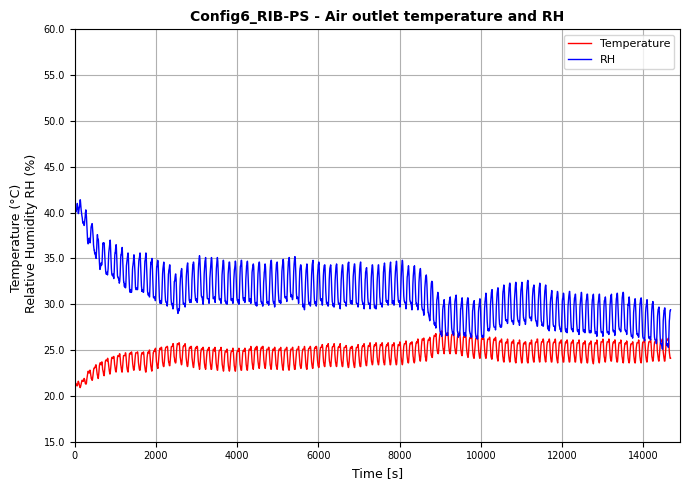

In [21]:
# Plot both curves on the same figure
plt.figure(figsize=(7, 5))

# Temperature curve
plt.plot(data_air_HR_T['Time [s]'], data_air_HR_T['Temperature'],
         linewidth=1.0, color='red', label='Temperature')

# HR curve
plt.plot(data_air_HR_T['Time [s]'], data_air_HR_T['HR'],
         linewidth=1.0, color='blue', label='RH')

# Labels and title
plt.xlabel("Time [s]", fontsize=9)
plt.ylabel("Temperature (°C) \n Relative Humidity RH (%)", fontsize=9)
plt.title(f"{n} - Air outlet temperature and RH", fontsize=10)

# Grid and ticks
plt.grid(True)
plt.xticks(fontsize=7)
plt.yticks(fontsize=7)

# Format Y-axis ticks
ax = plt.gca()
# ax.set_xlim(left=6000, right=8000)
ax.set_ylim(bottom=15, top=50)
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))

# Add legend in top-right corner
plt.legend(fontsize=8, loc='upper right')
plt.ylim(bottom=15, top=60)
# plt.xlim(0, 13100) # For Config3, Config4, Config5
plt.xlim(0,14900) # For Config6, Config7
# plt.vlines(x=7200, ymin=15, ymax=60, color='gray', linestyle='--', label='Start of test')
# Tight layout
plt.tight_layout()
plt.show()


Data extraction for the appropriate time interval

ELPI+ & Air speed & T-HR

In [22]:
# Récupérer les secondes ELPI+
Start_time_sec = data.loc[data['DateTime'] == Start_datetime, 'Time [s]'].values[0]
End_time_sec = data.loc[data['DateTime'] == End_datetime, 'Time [s]'].values[0]

# Fonction générique pour trouver la correspondance
def find_time_seconds(df, datetime_col, time_col, target_datetime):
    # S'assurer que target_datetime est un datetime
    target = pd.to_datetime(target_datetime)
    
    # Chercher la correspondance exacte
    mask = df[datetime_col] == target
    if mask.any():
        return df.loc[mask, time_col].values[0]
    
    # Sinon, chercher la valeur la plus proche
    df['temp_diff'] = abs(df[datetime_col] - target)
    closest_idx = df['temp_diff'].idxmin()
    closest_datetime = df.loc[closest_idx, datetime_col]
    result = df.loc[closest_idx, time_col]
    
    print(f"⚠️ Pas de correspondance exacte pour {target}")
    print(f"   → Utilisation de {closest_datetime} (différence: {(closest_datetime - target).total_seconds():.1f}s)")
    
    return result

# Récupérer les secondes Air speed
Start_time_sec_1 = find_time_seconds(data_air_speed, 'Date/Heure', 'Time [s]', Start_datetime)
End_time_sec_1 = find_time_seconds(data_air_speed, 'Date/Heure', 'Time [s]', End_datetime)

# Récupérer les secondes T-HR
Start_time_sec_2 = find_time_seconds(data_air_HR_T, 'Datetime', 'Time [s]', Start_datetime)
End_time_sec_2 = find_time_seconds(data_air_HR_T, 'Datetime', 'Time [s]', End_datetime)

print(f"✅ ELPI+: {Start_time_sec} → {End_time_sec}")
print(f"✅ Air speed: {Start_time_sec_1} → {End_time_sec_1}")
print(f"✅ T-HR: {Start_time_sec_2} → {End_time_sec_2}")

⚠️ Pas de correspondance exacte pour 2026-02-23 15:55:18
   → Utilisation de 2026-02-23 15:55:00 (différence: -18.0s)
⚠️ Pas de correspondance exacte pour 2026-02-23 11:55:00
   → Utilisation de 2026-02-23 11:55:02 (différence: 2.0s)
⚠️ Pas de correspondance exacte pour 2026-02-23 15:55:18
   → Utilisation de 2026-02-23 15:55:19 (différence: 1.0s)
✅ ELPI+: 248.0 → 14666.0
✅ Air speed: 240.0 → 14640.0
✅ T-HR: 220.0 → 14637.0


In [23]:
# # Récupérer les secondes ELPI+
# Start_time_sec = data.loc[data['DateTime'] == Start_datetime, 'Time [s]'].values[0]
# End_time_sec = data.loc[data['DateTime'] == End_datetime, 'Time [s]'].values[0]

# # Récupérer les secondes Air speed
# Start_time_sec_1 = data_air_speed.loc[data_air_speed['Date/Heure'] == Start_datetime, 'Time [s]'].values[0]
# End_time_sec_1 = data_air_speed.loc[data_air_speed['Date/Heure'] == End_datetime, 'Time [s]'].values[0]

# # Récupérer les secondes T-HR
# Start_time_sec_2 = data_air_HR_T.loc[data_air_HR_T['Datetime'] == Start_datetime, 'Time [s]'].values[0]
# End_time_sec_2 = data_air_HR_T.loc[data_air_HR_T['Datetime'] == End_datetime, 'Time [s]'].values[0]

Limitation for any Config

In [24]:
# Convertir lmin et lmax en entiers
lmin = int(Start_time_sec) #RIB-PS_ELPI
lmax = int(End_time_sec) #RIB-PS_ELPI

lmin_1 = int(Start_time_sec_1) #RIB-PS_AIR_OUTLET_SPEED
lmax_1 = int(End_time_sec_1) #RIB-PS_AIR_OUTLET_SPEED

lmin_2 = int(Start_time_sec_2) #RIB-PS_T_HR
lmax_2 = int(End_time_sec_2) #RIB-PS_T_HR

print(f"lmin = {lmin} sec")
print(f"lmax = {lmax} sec")
print(f"lmin_1 = {lmin_1} sec")
print(f"lmax_1 = {lmax_1} sec")
print(f"lmin_2 = {lmin_2} sec")
print(f"lmax_2 = {lmax_2} sec")

lmin = 248 sec
lmax = 14666 sec
lmin_1 = 240 sec
lmax_1 = 14640 sec
lmin_2 = 220 sec
lmax_2 = 14637 sec


Extracted files: ELPI+ & Speed & T-HR

In [25]:
extrait_physical_data = physical_data.iloc[lmin:lmax]
extrait_data = data.iloc[lmin:lmax]
extrait_data_air_speed = data_air_speed.iloc[lmin_1:lmax_1]
extrait_data_air_HR_T = data_air_HR_T.iloc[lmin_2:lmax_2]

###### Show extracted first and last

In [26]:
first_row = extrait_physical_data.iloc[[0]][extrait_physical_data.columns[:1]]
last_row = extrait_physical_data.iloc[[-1]][extrait_physical_data.columns[:1]]

print("First row:")
print(first_row)

print("\nLast row:")
print(last_row)

# Extract timestamp strings from the first column
first_time_str = str(first_row.iloc[0, 0])
last_time_str = str(last_row.iloc[0, 0])

first_time = parser.parse(first_time_str)
last_time = parser.parse(last_time_str)

# Calculate the duration in seconds and convert to minutes
duration_seconds = (last_time - first_time).total_seconds()
duration_minutes = duration_seconds / 60

# Print the duration
print(f"\nDuration between first and last row: {duration_minutes:.2f} minutes")

First row:
               DateTime
248 2026-02-23 11:55:00

Last row:
                 DateTime
14665 2026-02-23 15:55:17

Duration between first and last row: 240.28 minutes


In [27]:
# first_row = extrait_data_air_speed.iloc[[0]][extrait_data_air_speed.columns[:1]]
# last_row = extrait_data_air_speed.iloc[[-1]][extrait_data_air_speed.columns[:1]]

# print("First row:")
# print(first_row)

# print("\nLast row:")
# print(last_row)

# # Extract timestamp strings from the first column
# first_time_str = str(first_row.iloc[0, 0])
# last_time_str = str(last_row.iloc[0, 0])

# first_time = parser.parse(first_time_str)
# last_time = parser.parse(last_time_str)

# # Calculate the duration in seconds and convert to minutes
# duration_seconds = (last_time - first_time).total_seconds()
# duration_minutes = duration_seconds / 60

# # Print the duration
# print(f"\nDuration between first and last row: {duration_minutes:.2f} minutes")

Plot: Extracted raw data in current (fA) vs time

In [28]:
# fig, (ax1, ax2) = plt.subplots(ncols=2, gridspec_kw={'width_ratios':(1,0.5), 'wspace':0.1})
# fig.set_size_inches(w=30, h=8)

# fig.suptitle(f"{n}", y=0.92, fontweight='bold')

# ax1.plot(extrait_physical_data['Time [s]'], extrait_physical_data[extrait_physical_data.columns[1:-1]].sum(axis=1))
# ax1.set_ylabel('Total instantaneous current [fA]')
# ax1.set_xlabel('Time [s]')
# ax1.grid(alpha=0.2)
# ax1.set_xlim(left=0)
# ax1.set_ylim(bottom=0)
# ax1.margins(x=0)
# # ax1.set_xlim(200,2000)


# # Pour l'axe y de ax1 en notation scientifique
# ax1.yaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
# ax1.ticklabel_format(axis='y', style='sci', scilimits=(0,0))

# ax2.bar(extrait_physical_data.columns[1:-1].astype(float)*1000, height= extrait_physical_data[extrait_physical_data.columns[1:-1]].sum(axis=0),width=1000* extrait_physical_data.columns[1:-1].astype(float)/5 )
# ax2.set_xscale('log')
# ax2.set_xmargin(0)
# ax2.grid(alpha=0.2)
# ax2.set_ylabel('Instantaneous current [fA]')
# ax2.set_xlabel('Particles Dia. [nm]')
# ax2.set_yscale('log')
# # Pour l'axe y de ax2 en notation scientifique
# ax2.yaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
# ax2.ticklabel_format(axis='y', style='sci', scilimits=(0,0))

# # Ajout des étiquettes de diamètre sur chaque barre
# for bar, diameter in zip(ax2.patches, extrait_physical_data.columns[1:-1].astype(float) * 1000):
#     height = bar.get_height()
#     if height > 0:  # éviter log(0)
#         ax2.text(
#             bar.get_x() + bar.get_width()/2,
#             height * 1.1,
#             f"{diameter:.0f} nm",
#             ha='center',
#             va='bottom',
#             fontsize=10,
#             rotation=90
#         )

Plot: Extracted Total number concentration [#/cm3] vs time

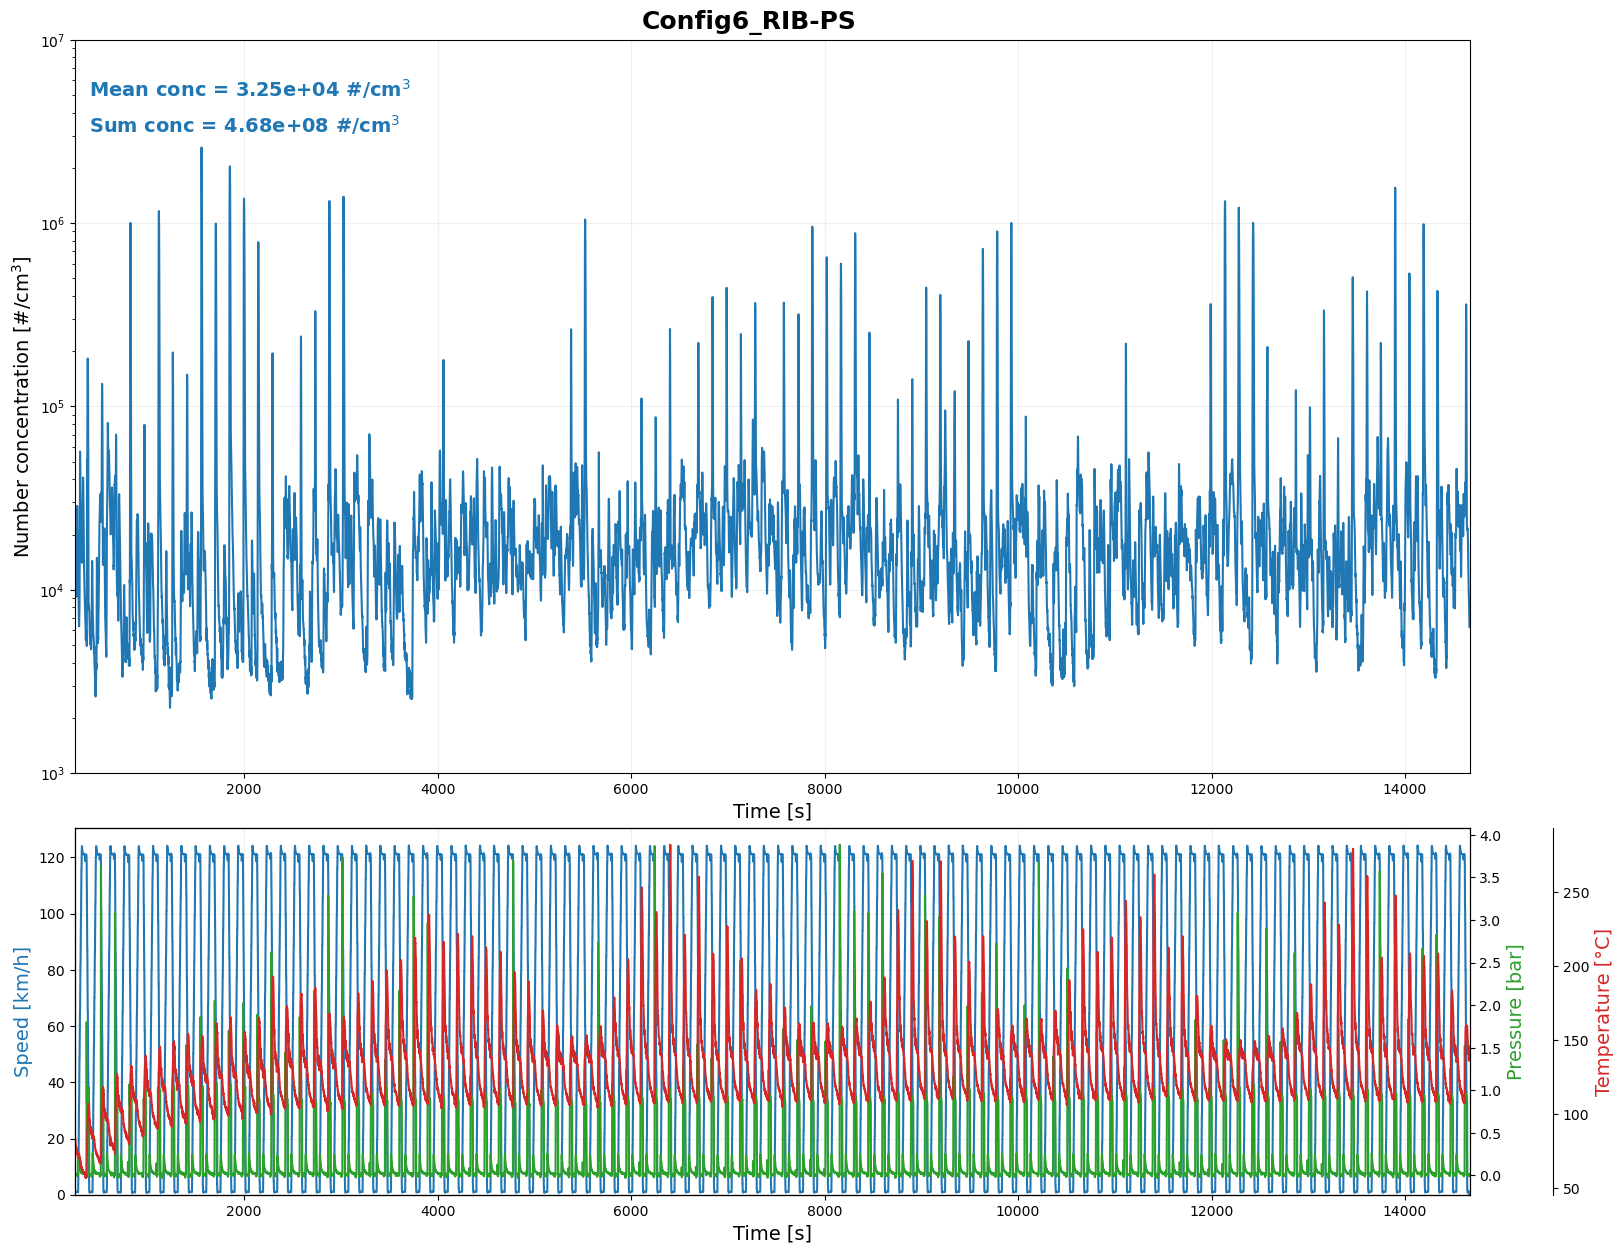

In [29]:
fig, (ax1, ax2)= plt.subplots(ncols=1,nrows=2, gridspec_kw={'height_ratios':(1,0.5), 'hspace':0.1})
fig.set_size_inches(w=18, h=15)
fig.suptitle(f"{n}", y=0.9, fontweight='bold')

# Limit of x-axis
time_min = lmin
time_max = lmax

# time_min = 3500
# time_max = 5000

# Plot number concentration
ax1.set_xlim(time_min, time_max)
ax1.plot(extrait_data['Time [s]'], extrait_data[extrait_data.columns[4]])
ax1.set_ylabel('Number concentration [#/cm$^3$]')
ax1.set_xlabel('Time [s]')
ax1.grid(alpha=0.2)
ax1.margins(x=0)
ax1.set_yscale('log')
ax1.set_ylim(bottom=1E3, top=1E7)
# ax1.set_ylim(bottom=1E3, top=8E5)

# Annotate mean and sum on the plot
mean_value = extrait_data[extrait_data.columns[4]].mean()
sum_value = extrait_data[extrait_data.columns[4]].sum()
ax1.text(0.01, 0.95, f'Mean conc = {mean_value:.2e} #/cm$^3$', transform=ax1.transAxes,
         fontsize=14, color='tab:blue', fontweight='bold',
         verticalalignment='top', horizontalalignment='left')
ax1.text(0.01, 0.90, f'Sum conc = {sum_value:.2e} #/cm$^3$', transform=ax1.transAxes,
         fontsize=14, color='tab:blue', fontweight='bold',
         verticalalignment='top', horizontalalignment='left')

# Plot Speed, Pressure, Temperature
ax2_1 = ax2.twinx()
ax2_2 = ax2.twinx()
ax2.set_xlim(time_min, time_max)
ax2.plot(extrait_data['Time [s]'], extrait_data['Speed']*(80/500), color='tab:blue') # RPM -> km/h
ax2_1.plot(extrait_data['Time [s]'], extrait_data['Pressure'], color='tab:green')
ax2_2.plot(extrait_data['Time [s]'], extrait_data['Temperature'], color='tab:red')
ax2.margins(x=0)
ax2.set_ylim(bottom=0)
ax2_2.spines['right'].set_position(('outward', 60))  # déplace le troisième axe y vers l'extérieur
ax2_2.set_ylabel('Temperature [°C]', color='tab:red')
ax2_1.set_ylabel('Pressure [bar]', color='tab:green')
ax2.set_ylabel('Speed [km/h]', color='tab:blue')
ax2.set_xlabel('Time [s]')
ax2.grid(alpha=0.2)

plt.show()

Plot: Extracted Total normalized number concentration [#/cm3] vs time

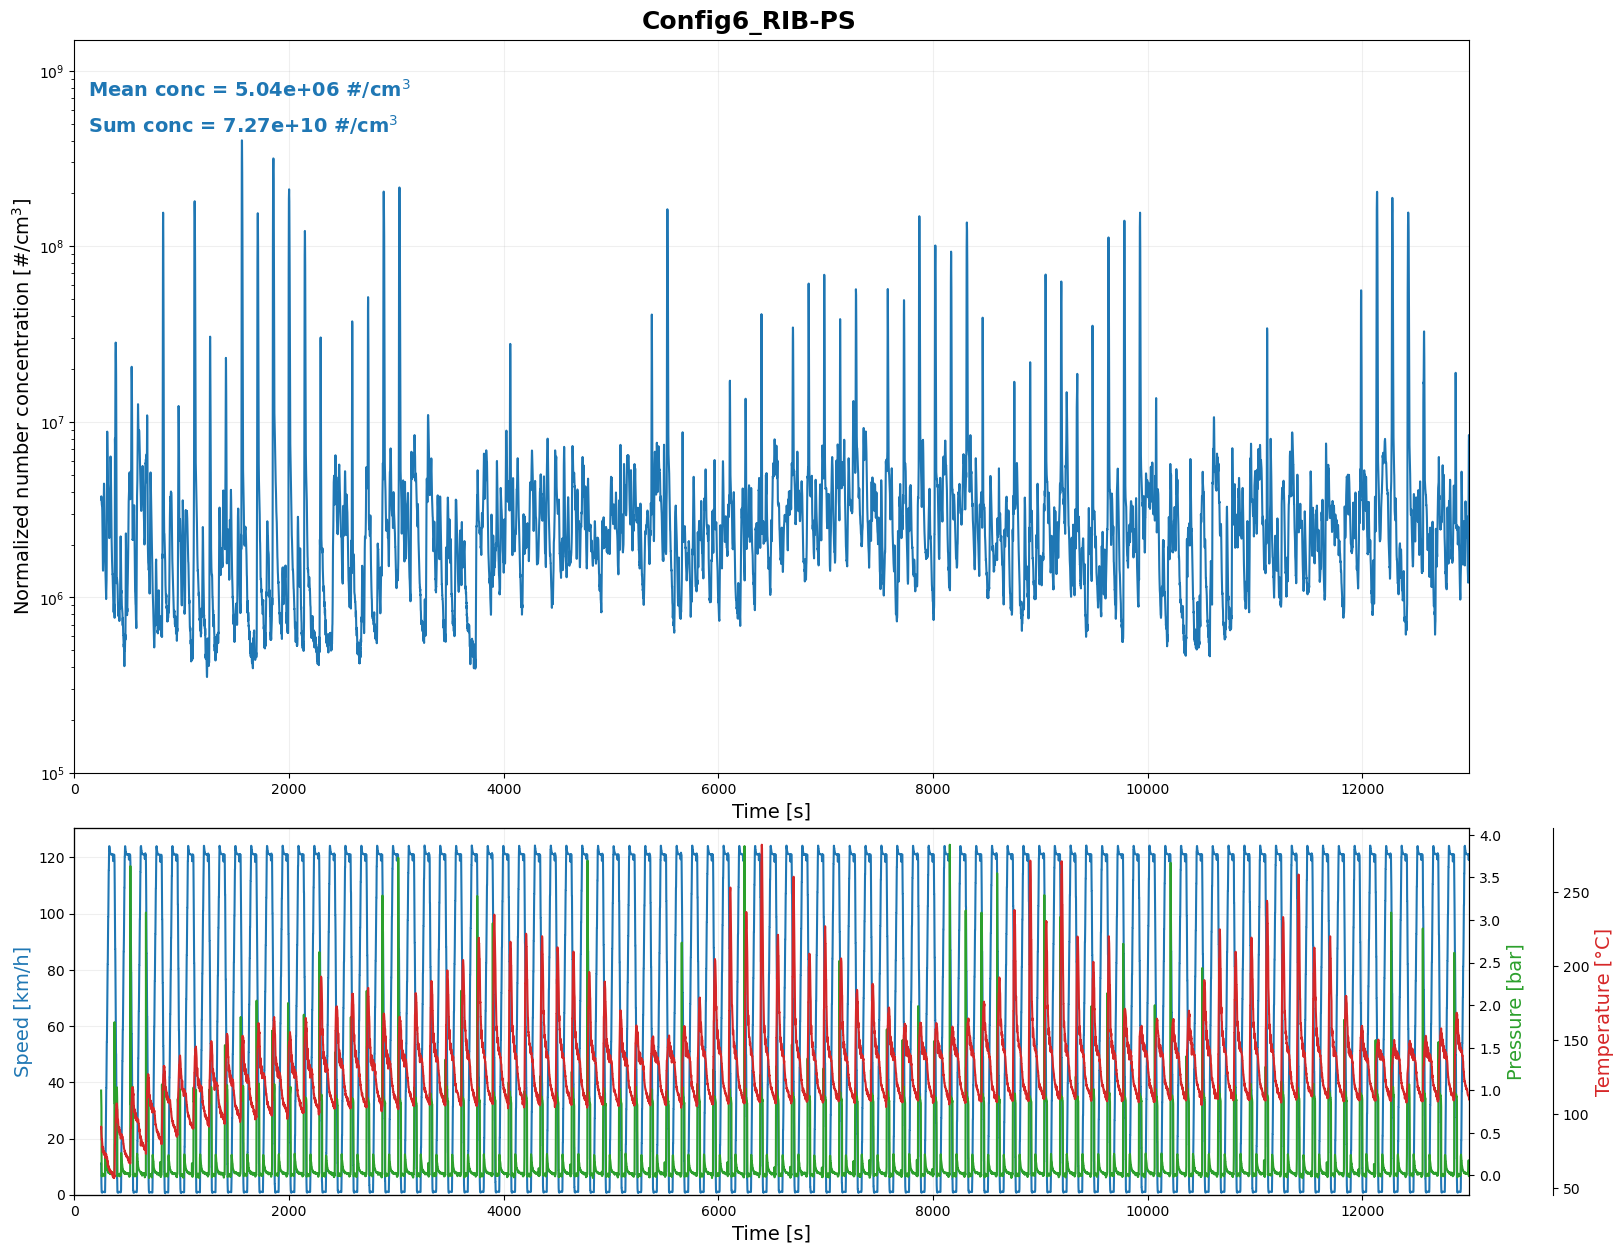

In [30]:
fig, (ax1, ax2)= plt.subplots(ncols=1,nrows=2, gridspec_kw={'height_ratios':(1,0.5), 'hspace':0.1})
fig.set_size_inches(w=18, h=15)
fig.suptitle(f"{n}", y=0.9, fontweight='bold')

# Limit of x-axis
# time_min = lmin
# time_max = lmax

time_min = 0
time_max = 13000

# Plot total normalized concentration
total_normalized_concentration = extrait_data.iloc[:, 5:-1].sum(axis=1)
ax1.plot(extrait_data['Time [s]'], total_normalized_concentration)
ax1.set_xlabel('Time [s]')
ax1.set_ylabel('Normalized number concentration [#/cm$^3$]')
ax1.grid(alpha=0.2)
ax1.margins(x=0)
ax1.set_yscale('log')
ax1.set_ylim(bottom=1E5, top=1.5E9)
# ax1.set_ylim(bottom=0, top=5.5E8)
ax1.set_xlim(time_min, time_max)

# Annotate mean and sum on the plot
mean_value_normalized = extrait_data.iloc[:, 5:-1].sum(axis=1).mean()
sum_value_normalized = extrait_data.iloc[:, 5:-1].sum(axis=1).sum()
ax1.text(0.01, 0.95, f'Mean conc = {mean_value_normalized:.2e} #/cm$^3$', transform=ax1.transAxes,
         fontsize=14, color='tab:blue', fontweight='bold',
         verticalalignment='top', horizontalalignment='left')
ax1.text(0.01, 0.90, f'Sum conc = {sum_value_normalized:.2e} #/cm$^3$', transform=ax1.transAxes,
         fontsize=14, color='tab:blue', fontweight='bold',
         verticalalignment='top', horizontalalignment='left')

# Plot Speed, Pressure, Temperature
ax2_1 = ax2.twinx()
ax2_2 = ax2.twinx()
ax2.plot(extrait_data['Time [s]'], extrait_data['Speed']*(80/500), color='tab:blue')
ax2_1.plot(extrait_data['Time [s]'], extrait_data['Pressure'], color='tab:green')
ax2_2.plot(extrait_data['Time [s]'], extrait_data['Temperature'], color='tab:red')
ax2.set_xlabel('Time [s]')
ax2_2.spines['right'].set_position(('outward', 60))  # déplace le troisième axe y vers l'extérieur
ax2_2.set_ylabel('Temperature [°C]', color='tab:red')
ax2_1.set_ylabel('Pressure [bar]', color='tab:green')   
ax2.set_ylabel('Speed [km/h]', color='tab:blue')
ax2.margins(x=0)
ax2.grid(alpha=0.2)
ax2.set_xlim(time_min, time_max)
ax2.set_ylim(bottom=0)

plt.show()

Plot: Air outlet speed vs time

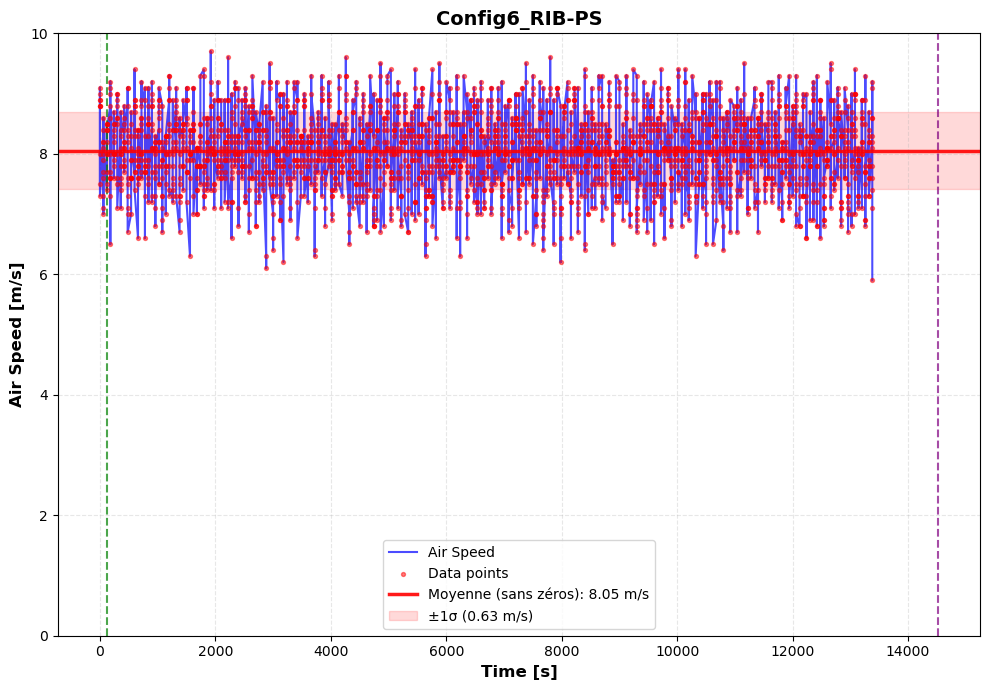

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ============================================
# CHARGEMENT ET PRÉTRAITEMENT DES DONNÉES
# ============================================

# Convertir la première colonne en datetime
extrait_data_air_speed[first_col] = pd.to_datetime(extrait_data_air_speed[first_col], errors='coerce')

# Identifier la première colonne
first_col = extrait_data_air_speed.columns[0]

# Trouver la première valeur NaN
first_nan = extrait_data_air_speed[first_col].isna().idxmax() if extrait_data_air_speed[first_col].isna().any() else len(extrait_data_air_speed)

# Garder seulement les lignes avant le premier NaN
extrait_data_air_speed = extrait_data_air_speed.iloc[:first_nan].copy()

# Garder uniquement les deux premières colonnes
extrait_data_air_speed = extrait_data_air_speed.iloc[:, :2]
extrait_data_air_speed.columns = ['Date/Heure', 'Air_speed']

# Nettoyer la colonne Air_speed (convertir les virgules en points)
extrait_data_air_speed['Air_speed'] = extrait_data_air_speed['Air_speed'].astype(str)
extrait_data_air_speed['Air_speed'] = extrait_data_air_speed['Air_speed'].str.replace(',', '.', regex=False)
extrait_data_air_speed['Air_speed'] = pd.to_numeric(extrait_data_air_speed['Air_speed'], errors='coerce')

# Supprimer les valeurs NaN
extrait_data_air_speed.dropna(subset=['Air_speed'], inplace=True)
extrait_data_air_speed.reset_index(drop=True, inplace=True)

# Calculer le temps en secondes depuis le début
start_time = extrait_data_air_speed['Date/Heure'].iloc[0]
extrait_data_air_speed['Time [s]'] = (extrait_data_air_speed['Date/Heure'] - start_time).dt.total_seconds()

# ============================================
# CALCUL DE LA MOYENNE DE VITESSE (SANS LES ZÉROS)
# ============================================

# Filtrer pour exclure les valeurs égales à zéro
air_speed_no_zeros = extrait_data_air_speed[extrait_data_air_speed['Air_speed'] > 0.01]  # Seuil > 0.01 pour exclure les zéros

# Alternative: exclure strictement les zéros
# air_speed_no_zeros = extrait_data_air_speed[extrait_data_air_speed['Air_speed'] != 0]

nb_zeros = len(extrait_data_air_speed[extrait_data_air_speed['Air_speed'] <= 0.01])
nb_total = len(extrait_data_air_speed)
nb_conserve = len(air_speed_no_zeros)

mean_air_speed = air_speed_no_zeros['Air_speed'].mean()
std_air_speed = air_speed_no_zeros['Air_speed'].std()

# ============================================
# CRÉATION DU GRAPHIQUE
# ============================================
plt.figure(figsize=(10, 7))

# Courbe principale en bleu
plt.plot(extrait_data_air_speed['Time [s]'], extrait_data_air_speed['Air_speed'], 
         'b-', linewidth=1.5, label='Air Speed', alpha=0.7)

# Points de données en rouge
plt.scatter(extrait_data_air_speed['Time [s]'], extrait_data_air_speed['Air_speed'], 
            c='red', s=8, label='Data points', alpha=0.5, zorder=5)

# LIGNE DE MOYENNE EN ROUGE (calculée SANS les zéros)
plt.axhline(y=mean_air_speed, color='red', linestyle='-', linewidth=2.5, 
            label=f'Moyenne (sans zéros): {mean_air_speed:.2f} m/s', alpha=0.9)

# Zone d'ombre pour l'écart-type (calculé sans les zéros)
plt.axhspan(mean_air_speed - std_air_speed, mean_air_speed + std_air_speed, 
            alpha=0.15, color='red', label=f'±1σ ({std_air_speed:.2f} m/s)')

# Lignes verticales spécifiques (à modifier selon vos besoins)
vline_times = [lmin_1 - 120, lmax_1 - 120]  # ← Modifier ces valeurs
colors = ['green', 'purple']
for i, vtime in enumerate(vline_times):
    plt.axvline(x=vtime, color=colors[i % len(colors)], 
                linestyle='--', linewidth=1.5, alpha=0.7)

# ============================================
# MISE EN FORME DU GRAPHIQUE
# ============================================
plt.xlabel('Time [s]', fontsize=12, fontweight='bold')
plt.ylim(0, 10)  # Ajustez les limites de l'axe Y selon vos données
plt.ylabel('Air Speed [m/s]', fontsize=12, fontweight='bold')
plt.title(n, fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3, linestyle='--')
plt.legend(loc='best', fontsize=10)
plt.tight_layout()
plt.show()

##### Modes: Extracted Total normalized number concentration vs Dp

Method1

In [32]:
# # Sum across rows for each diameter channel (columns from index 4 onward)
# somme_lignes = extrait_data.iloc[:, 5:-1].sum(axis=0) 
# diameters = somme_lignes.index.astype(float) * 1000 #Convert diameter indices to nanometers

# # Detect peaks in the summed data
# peaks, _ = find_peaks(somme_lignes.values)

# # Extract peak diameters and concentrations
# peak_diameters = diameters[peaks]
# peak_concentrations = somme_lignes.values[peaks]

# # Plot the curve and detected peaks
# plt.figure(figsize=(8, 5))
# plt.plot(diameters, somme_lignes, marker='o', markersize=3, linestyle='-', color='tab:blue')
# plt.plot(peak_diameters, peak_concentrations, "ro", markersize=3, label='Detected Peaks')

# # Annotate each peak
# for dp, conc in zip(peak_diameters, peak_concentrations):
#     plt.annotate(f"{dp:.1f} nm\n{conc:.1e}", xy=(dp, conc), xytext=(0, 5), textcoords='offset points', ha='center', fontsize=7.5, color='red')

# # Enhance plot aesthetics
# plt.title(f"{n}", fontsize=12)
# plt.xscale('log')
# plt.yscale('log')
# # plt.ylim(0,5e9)
# plt.xlabel("Dp [nm]", fontsize=10)
# plt.ylabel("Total normalized number \n concentration dN/dlogDp [#/cm$^3$]", fontsize=10)
# plt.grid(True)
# plt.legend()

# plt.tight_layout()
# plt.show()

Method2

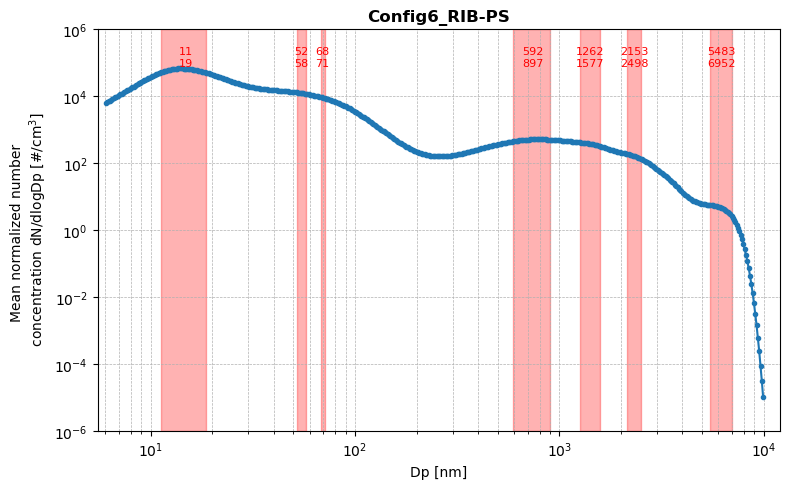

In [33]:
# Données
# somme_lignes = data.iloc[:, 5:-1].sum(axis=0)
somme_lignes = data.iloc[:, 5:-1].mean(axis=0)
diameters = somme_lignes.index.astype(float) * 1000  # nm
data = somme_lignes.values

# Paramètres
window = 5
threshold = 0.002  # 0.2%

# Calcul variation locale
local_variation = []
for i in range(window, len(data)-window):
    left_mean = np.mean(data[i-window:i])
    right_mean = np.mean(data[i+1:i+window+1])
    variation = (data[i] - (left_mean + right_mean)/2) / ((left_mean + right_mean)/2)
    local_variation.append(variation)

candidate_indices = [i+window for i, v in enumerate(local_variation) if v > threshold]

# Regrouper en fenêtres continues
windows = []
current_window = [candidate_indices[0]]
for idx in candidate_indices[1:]:
    if idx == current_window[-1] + 1:
        current_window.append(idx)
    else:
        windows.append(current_window)
        current_window = [idx]
windows.append(current_window)

# Calculer Dpmin et Dpmax pour chaque fenêtre
dp_ranges = [(diameters[min(w)], diameters[max(w)]) for w in windows]

# # Affichage
plt.figure(figsize=(8, 5))
plt.plot(diameters, data, marker='o', markersize=3, linestyle='-', color='tab:blue')

for dpmin, dpmax in dp_ranges:
    # Dessiner la zone rouge
    plt.axvspan(dpmin, dpmax, color='red', alpha=0.3)

    # Centre horizontal de la zone rouge
    x_center = (dpmin + dpmax) / 2

    # Position verticale dynamique (dans la zone rouge)
    y_top = plt.ylim()[1] * 2.5    # haut du graphique
    y_bottom = plt.ylim()[1] * 1.1 # juste en dessous

    # Afficher Dpmin en haut
    plt.annotate(f"{dpmin:.0f}",
                 xy=(x_center, y_top),
                 ha='center', color='red', fontsize=8)

    # Afficher Dpmax en dessous
    plt.annotate(f"{dpmax:.0f}",
                 xy=(x_center, y_bottom),
                 ha='center', color='red', fontsize=8)

plt.title(f"{n}", fontsize=12)
plt.xscale('log')

plt.yscale('log')
# plt.ylim(1e-1, 1e11)
plt.ylim(1e-6, 1e6)
plt.xlim(5.5, 1.2e4)
# plt.ylim(0,7e7)
# plt.ylim(0,1e5)

plt.xlabel("Dp [nm]", fontsize=10)
# plt.ylabel("Total normalized number \n concentration dN/dlogDp [#/cm$^3$]", fontsize=10)
plt.ylabel("Mean normalized number \n concentration dN/dlogDp [#/cm$^3$]", fontsize=10)
plt.grid(True, which="both", linestyle="--", linewidth=0.5)

plt.tight_layout()
plt.show()

##### Correction code for number and normalized number concentration (#/cm3)

In [34]:
# skip_after_braking = 25 # seconds to skip after braking
# # Extract relevant columns
# VPT = extrait_data[['Speed', 'Pressure', 'Temperature']] 
# Time = extrait_data.iloc[:, -1:] 

# # Detect braking phases
# braking_start= np.array([])
# braking_end= np.array([])
# for i in range(1,len(VPT)):
#     if (VPT['Pressure'].iloc[i]>1) & (VPT['Pressure'].iloc[i-1]<1):
#         braking_start = np.append(braking_start,i)
#     elif (VPT['Pressure'].iloc[i]<1) & (VPT['Pressure'].iloc[i-1]>1):
#         braking_end = np.append(braking_end,i)

# braking_start = np.array(braking_start)
# braking_end = np.array(braking_end)

# # Ensure each start has a corresponding end
# if len(braking_start)> len(braking_end): 
#     braking_start = braking_start[:-1]

# # Build braking DataFrame
# df_braking = pd.DataFrame()
# df_braking['Braking'] = np.arange(1,len(braking_start)+1)
# df_braking['Start'] = braking_start
# df_braking['End'] = braking_end + skip_after_braking

# df_braking['Duration_between'] = df_braking['Start'].shift(-1) - df_braking['End'] # Durée entre la fin d'un freinage et le début du suivant
# for i in range(len(df_braking)): 
#     if df_braking['Duration_between'].iloc[i]<0: # Si deux freinages se chevauchent, on réduit la fin du premier
#         df_braking['End'].iloc[i] = df_braking['End'].iloc[i] - 25
#     if i == len(df_braking)-1: # Pour le dernier freinage, on réduit la fin de dernier freinage de 20 secondes
#         df_braking['End'].iloc[i] = df_braking['End'].iloc[i] - 20

# df_braking.drop('Duration_between', axis=1, inplace=True)
# df_braking=df_braking.astype(dtype=int)

# # Read EP_Number and EP_Normalized
# EP_Number = extrait_data.iloc[:, 4:5]
# EP_Normalized = extrait_data.iloc[:, 5:-1]

# # Correct EP_Number
# EP_Number_corr = pd.DataFrame()
# for i in tqdm(range(len(df_braking)),desc='Braking'):
#     if i == 0:
#         for j in np.arange(0,df_braking['End'].iloc[i]):
#             d = pd.DataFrame(data=EP_Number.iloc[j]-EP_Number.iloc[0:df_braking['Start'].iloc[i]].mean())
#             EP_Number_corr = pd.concat([EP_Number_corr,d.T],ignore_index=True)
    
#     else:
#         for j in np.arange(df_braking['End'].iloc[i-1],df_braking['End'].iloc[i]):
#             d = pd.DataFrame(data=EP_Number.iloc[j]-EP_Number.iloc[df_braking['End'].iloc[i-1]:df_braking['Start'].iloc[i]].mean())
#             EP_Number_corr = pd.concat([EP_Number_corr,d.T],ignore_index=True)
# EP_Number_corr[EP_Number_corr < 0] = 0

# # Correct EP_Normalized
# EP_Normalized_corr = pd.DataFrame()
# for i in tqdm(range(len(df_braking)),desc='Braking'):
#     if i == 0:
#         for j in np.arange(0,df_braking['End'].iloc[i]):
#             d = pd.DataFrame(data=EP_Normalized.iloc[j]-EP_Normalized.iloc[0:df_braking['Start'].iloc[i]].mean())
#             EP_Normalized_corr = pd.concat([EP_Normalized_corr,d.T],ignore_index=True)
    
#     else:
#         for j in np.arange(df_braking['End'].iloc[i-1],df_braking['End'].iloc[i]):
#             d = pd.DataFrame(data=EP_Normalized.iloc[j]-EP_Normalized.iloc[df_braking['End'].iloc[i-1]:df_braking['Start'].iloc[i]].mean())
#             EP_Normalized_corr = pd.concat([EP_Normalized_corr,d.T],ignore_index=True)
# EP_Normalized_corr[EP_Normalized_corr < 0] = 0

# # Add Time, Speed, Pressure to corrected DataFrames
# EP_Number_corr = pd.concat([Time.iloc[:len(EP_Number_corr)].reset_index(drop=True), VPT.iloc[:len(EP_Number_corr)].reset_index(drop=True), EP_Number_corr["Total number"].reset_index(drop=True)], axis=1)
# EP_Normalized_corr = pd.concat([Time.iloc[:len(EP_Normalized_corr)].reset_index(drop=True), VPT.iloc[:len(EP_Normalized_corr)].reset_index(drop=True), EP_Normalized_corr.iloc[:, 0:].reset_index(drop=True)], axis=1)

# # Save corrected DataFrames
# output_folder = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\ELPI_corrected_data"

# # Save with specific n : name
# EP_Number_corr.to_csv(fr"{output_folder}\{n}\EP_Number_corr.csv", index=False)
# EP_Normalized_corr.to_csv(fr"{output_folder}\{n}\EP_Normalized_corr.csv", index=False)


In [35]:
# import numpy as np
# import pandas as pd
# from tqdm import tqdm

skip_after_braking = 25  # seconds to skip after braking

# Extract relevant columns
VPT = extrait_data[['Speed', 'Pressure', 'Temperature']] 
Time = extrait_data.iloc[:, -1:] 

# Detect braking phases
braking_start = []
braking_end = []

for i in range(1, len(VPT)):
    if (VPT['Pressure'].iloc[i] > 1) and (VPT['Pressure'].iloc[i-1] < 1):
        braking_start.append(i)
    elif (VPT['Pressure'].iloc[i] < 1) and (VPT['Pressure'].iloc[i-1] > 1):
        braking_end.append(i)

# Convert to numpy arrays
braking_start = np.array(braking_start)
braking_end = np.array(braking_end)

# Ensure each start has a corresponding end (handle both cases)
if len(braking_start) > len(braking_end):
    braking_start = braking_start[:len(braking_end)]
elif len(braking_end) > len(braking_start):
    braking_end = braking_end[:len(braking_start)]

# Verify we have at least one braking event
if len(braking_start) == 0 or len(braking_end) == 0:
    print("No valid braking events detected")
    # Handle empty case appropriately
    EP_Number_corr = pd.DataFrame()
    EP_Normalized_corr = pd.DataFrame()
else:
    # Build braking DataFrame
    df_braking = pd.DataFrame()
    df_braking['Braking'] = np.arange(1, len(braking_start) + 1)
    df_braking['Start'] = braking_start
    df_braking['End'] = braking_end + skip_after_braking

    df_braking['Duration_between'] = df_braking['Start'].shift(-1) - df_braking['End']
    
    # Modify End values safely
    for i in range(len(df_braking)):
        if df_braking['Duration_between'].iloc[i] < 0:
            df_braking.loc[i, 'End'] = df_braking.loc[i, 'End'] - 25
        if i == len(df_braking) - 1:
            df_braking.loc[i, 'End'] = df_braking.loc[i, 'End'] - 20

    df_braking.drop('Duration_between', axis=1, inplace=True)
    df_braking = df_braking.astype(dtype=int)

    # Read EP_Number and EP_Normalized
    EP_Number = extrait_data.iloc[:, 4:5]
    EP_Normalized = extrait_data.iloc[:, 5:-1]

    # Correct EP_Number
    EP_Number_corr = pd.DataFrame()
    for i in tqdm(range(len(df_braking)), desc='Correcting EP_Number'):
        if i == 0:
            for j in np.arange(0, df_braking['End'].iloc[i]):
                d = pd.DataFrame(data=EP_Number.iloc[j] - EP_Number.iloc[0:df_braking['Start'].iloc[i]].mean())
                EP_Number_corr = pd.concat([EP_Number_corr, d.T], ignore_index=True)
        else:
            for j in np.arange(df_braking['End'].iloc[i-1], df_braking['End'].iloc[i]):
                d = pd.DataFrame(data=EP_Number.iloc[j] - EP_Number.iloc[df_braking['End'].iloc[i-1]:df_braking['Start'].iloc[i]].mean())
                EP_Number_corr = pd.concat([EP_Number_corr, d.T], ignore_index=True)
    
    EP_Number_corr[EP_Number_corr < 0] = 0

    # Correct EP_Normalized
    EP_Normalized_corr = pd.DataFrame()
    for i in tqdm(range(len(df_braking)), desc='Correcting EP_Normalized'):
        if i == 0:
            for j in np.arange(0, df_braking['End'].iloc[i]):
                d = pd.DataFrame(data=EP_Normalized.iloc[j] - EP_Normalized.iloc[0:df_braking['Start'].iloc[i]].mean())
                EP_Normalized_corr = pd.concat([EP_Normalized_corr, d.T], ignore_index=True)
        else:
            for j in np.arange(df_braking['End'].iloc[i-1], df_braking['End'].iloc[i]):
                d = pd.DataFrame(data=EP_Normalized.iloc[j] - EP_Normalized.iloc[df_braking['End'].iloc[i-1]:df_braking['Start'].iloc[i]].mean())
                EP_Normalized_corr = pd.concat([EP_Normalized_corr, d.T], ignore_index=True)
    
    EP_Normalized_corr[EP_Normalized_corr < 0] = 0

    # Add Time, Speed, Pressure to corrected DataFrames
    EP_Number_corr = pd.concat([Time.iloc[:len(EP_Number_corr)].reset_index(drop=True), 
                                VPT.iloc[:len(EP_Number_corr)].reset_index(drop=True), 
                                EP_Number_corr["Total number"].reset_index(drop=True)], axis=1)
    
    EP_Normalized_corr = pd.concat([Time.iloc[:len(EP_Normalized_corr)].reset_index(drop=True), 
                                    VPT.iloc[:len(EP_Normalized_corr)].reset_index(drop=True), 
                                    EP_Normalized_corr.iloc[:, 0:].reset_index(drop=True)], axis=1)

# Save corrected DataFrames
output_folder = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\ELPI_corrected_data"

# Save with specific n : name
EP_Number_corr.to_csv(fr"{output_folder}\{n}\EP_Number_corr.csv", index=False)
EP_Normalized_corr.to_csv(fr"{output_folder}\{n}\EP_Normalized_corr.csv", index=False)

Correcting EP_Normalized: 100%|██████████| 126/126 [01:45<00:00,  1.20it/s]


Reading the corrected files for each configuration: number and normalized number

In [36]:
# #Config3
# EP_Number_corr = pd.read_csv(r"c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\ELPI_corrected_data\Config3_RIB-PS\EP_Number_corr.csv")
# EP_Normalized_corr = pd.read_csv(r"c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\ELPI_corrected_data\Config3_RIB-PS\EP_Normalized_corr.csv")

#Config4
# EP_Number_corr = pd.read_csv(r"c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\ELPI_corrected_data\Config4_RIB-PS\EP_Number_corr.csv")
# EP_Normalized_corr = pd.read_csv(r"c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\ELPI_corrected_data\Config4_RIB-PS\EP_Normalized_corr.csv")

# #Config5
# EP_Number_corr = pd.read_csv(r"c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\ELPI_corrected_data\Config5_RIB-PS\EP_Number_corr.csv")
# EP_Normalized_corr = pd.read_csv(r"c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\ELPI_corrected_data\Config5_RIB-PS\EP_Normalized_corr.csv")

# #Config6
# EP_Number_corr = pd.read_csv(r"c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\ELPI_corrected_data\Config6_RIB-PS\EP_Number_corr.csv")
# EP_Normalized_corr = pd.read_csv(r"c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\ELPI_corrected_data\Config6_RIB-PS\EP_Normalized_corr.csv")

# #Config7
EP_Number_corr = pd.read_csv(r"c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\ELPI_corrected_data\Config7_RIB-PS\EP_Number_corr.csv")
EP_Normalized_corr = pd.read_csv(r"c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\ELPI_corrected_data\Config7_RIB-PS\EP_Normalized_corr.csv")

Plot: Corrected Extracted Total number concentration [#/cm3] vs time

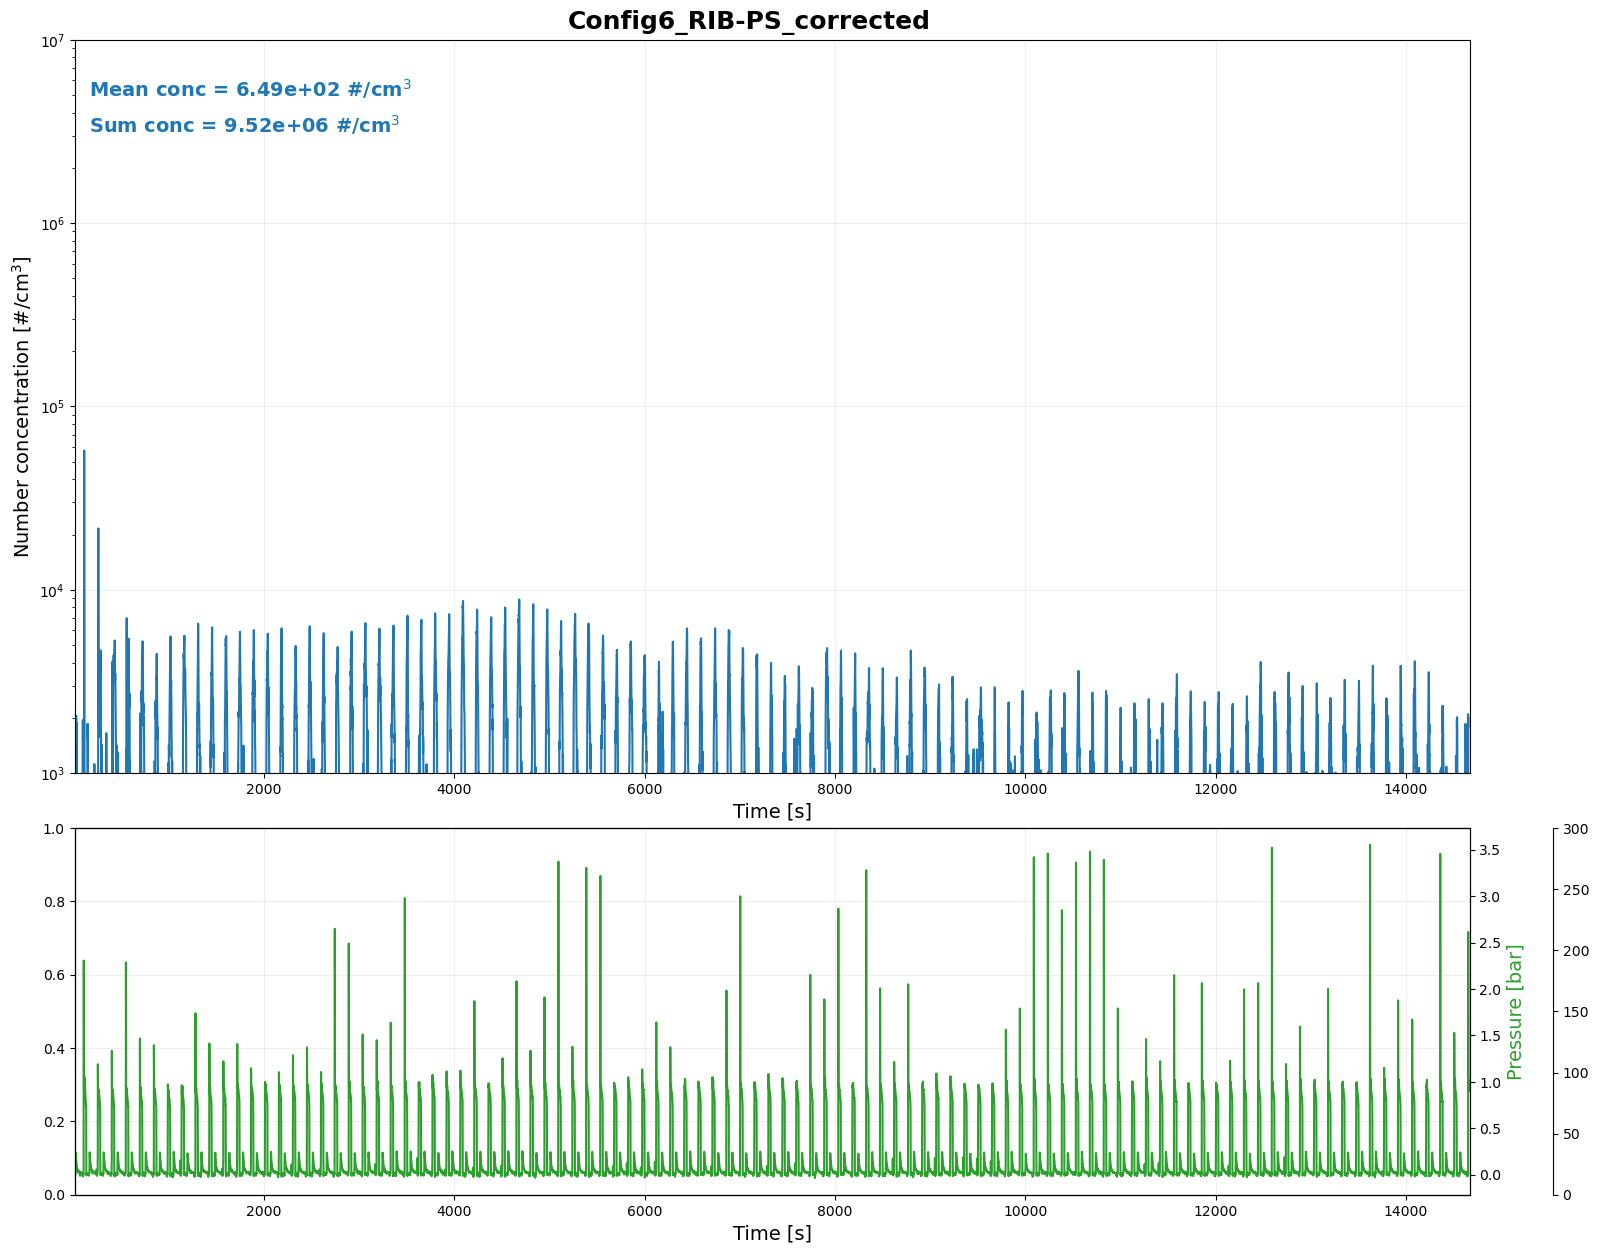

In [37]:
fig, (ax1, ax2)= plt.subplots(ncols=1,nrows=2, gridspec_kw={'height_ratios':(1,0.5), 'hspace':0.1})
fig.set_size_inches(w=18, h=15)
fig.suptitle(f"{n}_corrected", y=0.9, fontweight='bold')

# Plot Total Number vs Time
time_min = EP_Number_corr['Time [s]'].iloc[0]
time_max = EP_Number_corr['Time [s]'].iloc[-1]
ax1.plot(EP_Number_corr['Time [s]'], EP_Number_corr["Total number"])
ax1.set_xlim(time_min, time_max)
ax1.set_xlabel('Time [s]')
ax1.set_ylabel('Number concentration [#/cm$^3$]')
ax1.set_yscale('log')
# ax1.set_ylim(bottom=1E3, top=8E5)
ax1.set_ylim(bottom=1E3, top=1E7)
ax1.grid(alpha=0.2)
ax1.margins(x=0)

# Annotate mean and sum
mean_value = EP_Number_corr["Total number"].mean()
sum_value = EP_Number_corr["Total number"].sum()
ax1.text(0.01, 0.95, f'Mean conc = {mean_value:.2e} #/cm$^3$', transform=ax1.transAxes,
         fontsize=14, color='tab:blue', fontweight='bold',
         verticalalignment='top', horizontalalignment='left')
ax1.text(0.01, 0.90, f'Sum conc = {sum_value:.2e} #/cm$^3$', transform=ax1.transAxes,
         fontsize=14, color='tab:blue', fontweight='bold',
         verticalalignment='top', horizontalalignment='left')

# Plot Speed, Pressure, Temperature on ax2
ax2_1 = ax2.twinx()
ax2_2 = ax2.twinx()
# ax2.plot(EP_Number_corr['Time [s]'], EP_Number_corr['Speed']*(80/500), color='tab:blue') # RPM -> km/h
ax2_1.plot(EP_Number_corr['Time [s]'], EP_Number_corr['Pressure'], color='tab:green')
# ax2_2.plot(EP_Number_corr['Time [s]'], EP_Number_corr['Temperature'], color='tab:red')
ax2.set_xlabel('Time [s]')
# ax2.set_ylabel('Speed [km/h]', color='tab:blue')
ax2_1.set_ylabel('Pressure [bar]', color='tab:green')
# ax2_2.set_ylabel('Temperature [°C]', color='tab:red')
ax2_2.spines['right'].set_position(('outward', 60))  # déplace le troisième axe y vers l'extérieur
ax2_2.set_ylim(0,300)
ax2.grid(alpha=0.2)
ax2.set_xlim(time_min, time_max)
ax2.set_ylim(bottom=0)
ax2.margins(x=0)

# ax1.axvline(x=13100, color='grey', linestyle='--') 
# ax2.axvline(x=13100, color='grey', linestyle='--') 

plt.tight_layout()
plt.show()

Plot: Corrected Extracted Total normalized number concentration [#/cm3] vs time

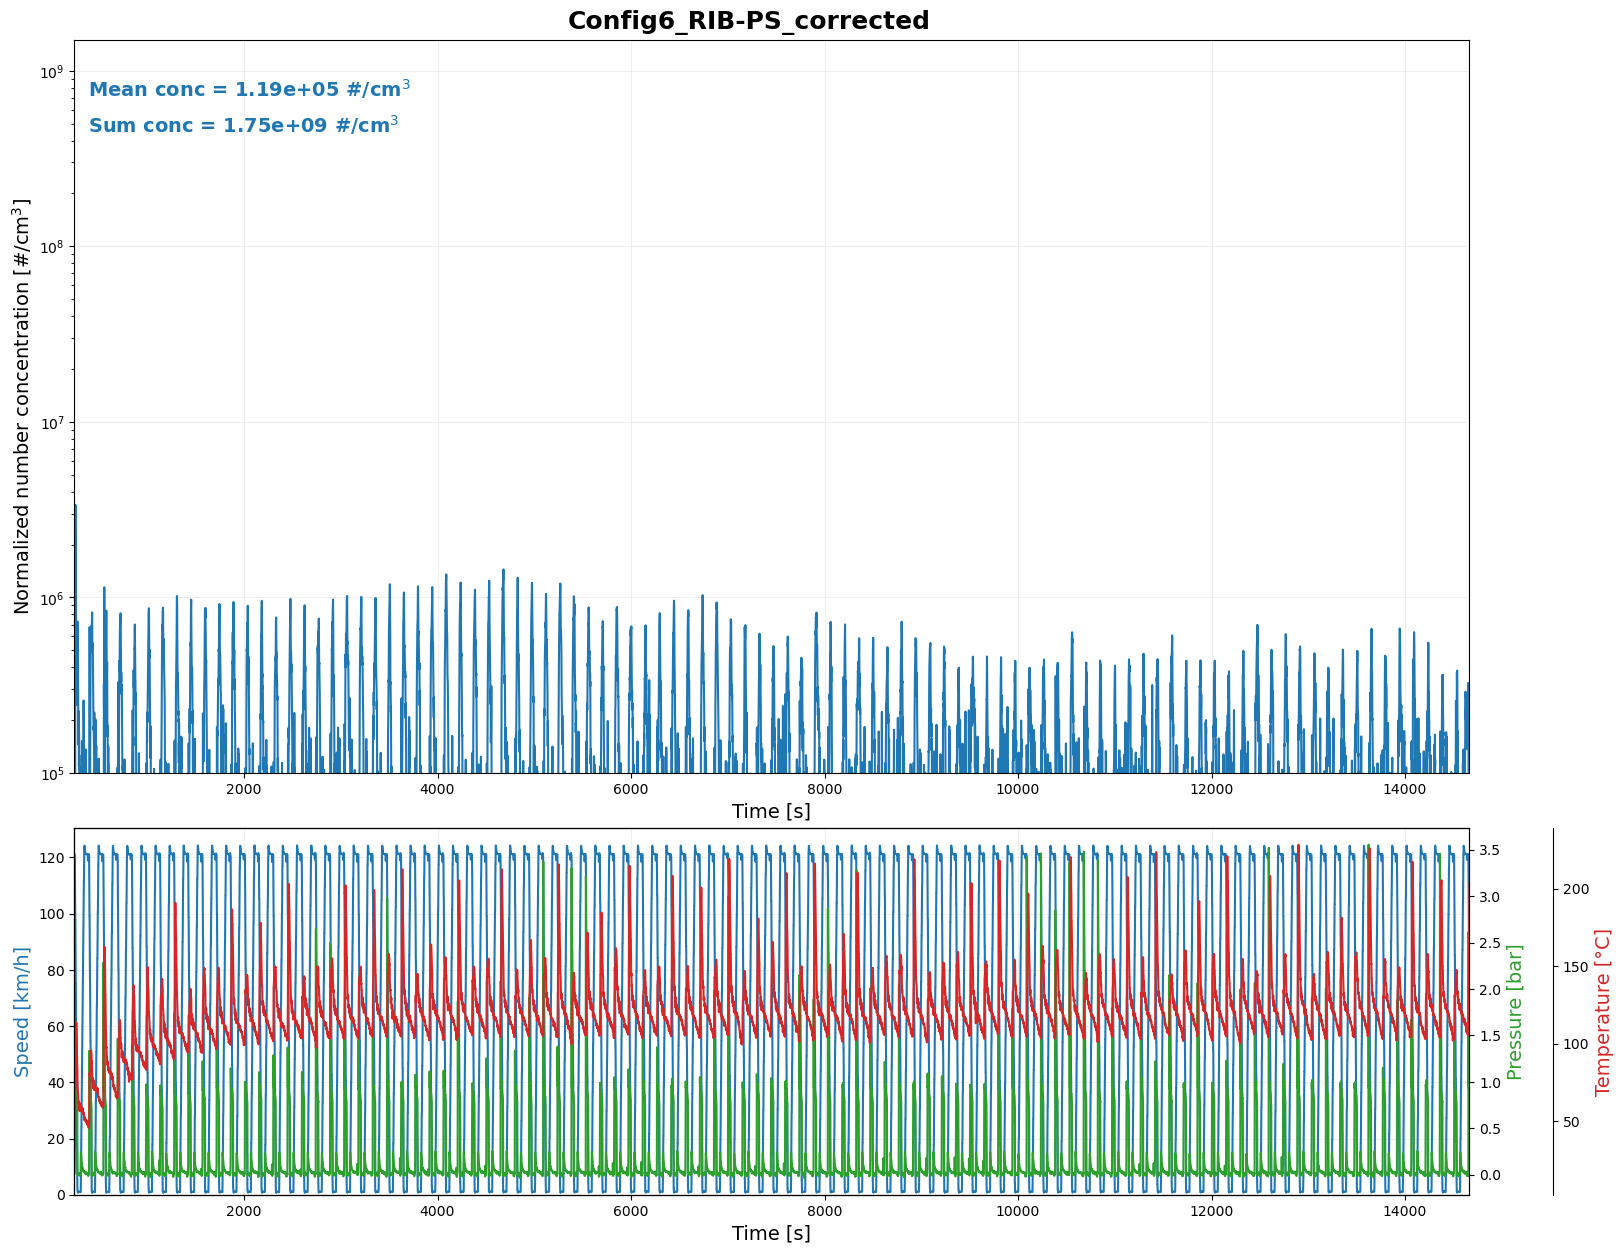

In [38]:
fig, (ax1, ax2)= plt.subplots(ncols=1,nrows=2, gridspec_kw={'height_ratios':(1,0.5), 'hspace':0.1})
fig.set_size_inches(w=18, h=15)
fig.suptitle(f"{n}_corrected", y=0.9, fontweight='bold')

time_min = lmin
time_max = lmax

# time_min = 150
# time_max = 750

# Plot Total Normalized number vs Time
total_normalized_concentration = EP_Normalized_corr.iloc[:, 4:].sum(axis=1)
ax1.plot(EP_Normalized_corr['Time [s]'], total_normalized_concentration)
ax1.set_xlabel('Time [s]')
ax1.set_ylabel('Normalized number concentration [#/cm$^3$]')
ax1.grid(alpha=0.2)
ax1.margins(x=0)
ax1.set_xlim(left=0)
ax1.set_yscale('log')
ax1.set_ylim(bottom=1E5, top=1.5E9)
# ax1.set_ylim(bottom=0, top=5.5E8)
ax1.set_xlim(time_min, time_max)

# Annotate mean and sum
mean_value_normalized = EP_Normalized_corr.iloc[:, 4:].sum(axis=1).mean()
sum_value_normalized = EP_Normalized_corr.iloc[:, 4:].sum(axis=1).sum()
# Annotation en haut à gauche
ax1.text(0.01, 0.95, f'Mean conc = {mean_value_normalized:.2e} #/cm$^3$', transform=ax1.transAxes,
         fontsize=14, color='tab:blue', fontweight='bold',
         verticalalignment='top', horizontalalignment='left')
ax1.text(0.01, 0.90, f'Sum conc = {sum_value_normalized:.2e} #/cm$^3$', transform=ax1.transAxes,
         fontsize=14, color='tab:blue', fontweight='bold',
         verticalalignment='top', horizontalalignment='left')

ax2_1 = ax2.twinx()
ax2_2 = ax2.twinx()
ax2.plot(EP_Normalized_corr['Time [s]'], EP_Normalized_corr['Speed']*(80/500), color='tab:blue')
ax2_1.plot(EP_Normalized_corr['Time [s]'], EP_Normalized_corr['Pressure'], color='tab:green')
ax2_2.plot(EP_Normalized_corr['Time [s]'], EP_Normalized_corr['Temperature'], color='tab:red')
ax2.set_xlabel('Time [s]')
ax2_2.spines['right'].set_position(('outward', 60))  # déplace le troisième axe y vers l'extérieur
ax2_2.set_ylabel('Temperature [°C]', color='tab:red')
ax2_1.set_ylabel('Pressure [bar]', color='tab:green')   
ax2.set_ylabel('Speed [km/h]', color='tab:blue')
ax2.margins(x=0)
ax2.grid(alpha=0.2)
ax2.set_ylim(bottom=0)
ax2.set_xlim(time_min, time_max)

plt.tight_layout()
plt.show()

Modes: Corrected Total normalized number concentration vs Dp

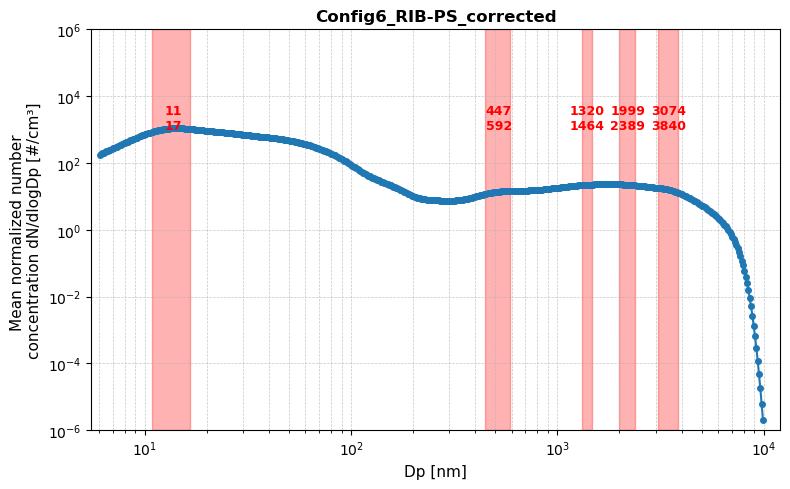


=== Résultats pour Config6_RIB-PS ===
Nombre de pics détectés: 5
Pic 1: 10.8 - 16.6 nm (largeur: 5.8 nm)
Pic 2: 446.7 - 592.2 nm (largeur: 145.5 nm)
Pic 3: 1319.6 - 1464.0 nm (largeur: 144.4 nm)
Pic 4: 1999.2 - 2388.8 nm (largeur: 389.6 nm)
Pic 5: 3074.2 - 3840.4 nm (largeur: 766.3 nm)


In [39]:
# Données avec EP_Normalized_corr
# Les colonnes de diamètres commencent à partir de l'index 4 (colonne '0.006045')
somme_lignes = EP_Normalized_corr.iloc[:, 4:].mean(axis=0)  # mean sur toutes les colonnes de diamètres
diameters = somme_lignes.index.astype(float) * 1000  # Convertir en nm (0.006045 µm -> 6.045 nm)
data = somme_lignes.values

# Paramètres
window = 5
threshold = 0.002  # 0.2%

# Calcul variation locale
local_variation = []
for i in range(window, len(data)-window):
    left_mean = np.mean(data[i-window:i])
    right_mean = np.mean(data[i+1:i+window+1])
    variation = (data[i] - (left_mean + right_mean)/2) / ((left_mean + right_mean)/2)
    local_variation.append(variation)

candidate_indices = [i+window for i, v in enumerate(local_variation) if v > threshold]

# Regrouper en fenêtres continues
windows = []
if len(candidate_indices) > 0:
    current_window = [candidate_indices[0]]
    for idx in candidate_indices[1:]:
        if idx == current_window[-1] + 1:
            current_window.append(idx)
        else:
            windows.append(current_window)
            current_window = [idx]
    windows.append(current_window)
    
    # Calculer Dpmin et Dpmax pour chaque fenêtre
    dp_ranges = [(diameters[min(w)], diameters[max(w)]) for w in windows]
else:
    dp_ranges = []
    print("Aucune variation significative détectée")

# Affichage
plt.figure(figsize=(8, 5))
plt.plot(diameters, data, marker='o', markersize=4, linestyle='-', color='tab:blue', linewidth=1.5)

# Colorer les zones détectées
for dpmin, dpmax in dp_ranges:
    # Dessiner la zone rouge
    plt.axvspan(dpmin, dpmax, color='red', alpha=0.3)
    
    # Centre horizontal de la zone rouge
    x_center = (dpmin + dpmax) / 2
    
    # Position verticale (au sommet du graphique)
    y_pos = plt.ylim()[1] * 0.9
    
    # Afficher l'intervalle
    plt.annotate(f"{dpmin:.0f}\n{dpmax:.0f}",
                 xy=(x_center, y_pos),
                 ha='center', color='red', fontsize=9, fontweight='bold')

plt.title(f"{n}_corrected", fontsize=12, fontweight='bold')
plt.xscale('log')
plt.yscale('log')
plt.ylim(1e-6, 1e6)
plt.xlim(5.5, 1.2e4)

plt.xlabel("Dp [nm]", fontsize=11)
plt.ylabel("Mean normalized number \nconcentration dN/dlogDp [#/cm³]", fontsize=11)
plt.grid(True, which="both", linestyle="--", linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.show()

# Afficher les résultats
if dp_ranges:
    print(f"\n=== Résultats pour {n} ===")
    print(f"Nombre de pics détectés: {len(dp_ranges)}")
    for i, (dpmin, dpmax) in enumerate(dp_ranges, 1):
        print(f"Pic {i}: {dpmin:.1f} - {dpmax:.1f} nm (largeur: {dpmax-dpmin:.1f} nm)")
else:
    print(f"\nAucun pic détecté pour {n} avec threshold={threshold}")

PM10, PM2.5, PM1 and PM0.1

In [40]:
# PM0.1 : de 0.006045 à ≤ 0.1 µm → tous les diamètres ≤ 0.1 µm {190 channels}
PM0_1 = EP_Normalized_corr.iloc[:, 4:194].sum(axis=1).sum(axis=0)

# PM1 : de 0.006045 à 1 µm → tous les diamètres ≤ 1 µm
PM1 = EP_Normalized_corr.iloc[:, 4:349].sum(axis=1).sum(axis=0)

# PM2.5 : de 0.006045 à 2.5 µm → tous les diamètres ≤ 2.5 µm
PM2_5 = EP_Normalized_corr.iloc[:, 4:411].sum(axis=1).sum(axis=0)

# PM10 : de 0.006045 à 9.926089 µm → toute la liste des diamètres
PM10 = EP_Normalized_corr.iloc[:, 4:].sum(axis=1).sum(axis=0)

print(f"PM0.1: {PM0_1:.3e} #/cm3")
print(f"PM1: {PM1:.3e} #/cm3")
print(f"PM2.5: {PM2_5:.3e} #/cm3")
print(f"PM10: {PM10:.3e} #/cm3")


PM0.1: 1.678e+09 #/cm3
PM1: 1.719e+09 #/cm3
PM2.5: 1.738e+09 #/cm3
PM10: 1.749e+09 #/cm3


PM10, PM2.5, PM1 and PM0.1 for configx

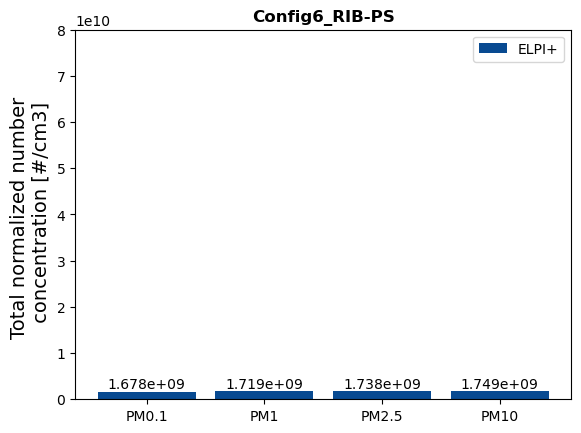

In [41]:
# Données
categories = ['PM0.1', 'PM1', 'PM2.5', 'PM10']
valeurs = [PM0_1, PM1, PM2_5, PM10]

x = np.arange(len(categories)) * 0.6  # facteur < 1 pour rapprocher les barres
width = 0.5  # largeur des barres réduite

# Dégradé doux de vert
colormap = cm.get_cmap('Blues')
couleurs = [colormap(i) for i in np.linspace(0.9, 0.9, len(categories))]

fig, ax = plt.subplots()
bars = ax.bar(x, valeurs, width=width, color=couleurs, label='ELPI+')

# Ajouter les valeurs au-dessus des barres
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 0.5, f'{height:.3e}',
            ha='center', va='bottom', fontsize=10)

# Titre et labels
ax.set_title(f"{n}", fontsize=12)
ax.set_ylabel('Total normalized number \n concentration [#/cm3]')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.legend()

# ax.set_yscale('log')
# ax.set_ylim(7.02e10, 7.2e10) #config 3,4
# ax.set_ylim(6.8e10, 7.2e10) #config 5
# ax.set_ylim(2e10, 5e10) #config 6
ax.set_ylim(0, 8e10) #config 6_ Scale X61
# ax.set_ylim(1e10, 1e11) #config 7
plt.show()

In [42]:
# import numpy as np
# import matplotlib.pyplot as plt
# from matplotlib.ticker import ScalarFormatter

# categories = ['PM10', 'PM2.5', 'PM1', 'PM0.1']  # PM10 en premier
# valeurs = [PM10, PM2_5, PM1, PM0_1]
# # ... puis après set_yticklabels
# ax.invert_yaxis()  # Inverse pour que PM10 (premier) aille en haut

# fig, ax = plt.subplots(figsize=(9, 5))

# # Barres horizontales
# y_pos = np.arange(len(categories))
# bars = ax.barh(y_pos, valeurs, height=0.6, 
#                color=plt.cm.Blues(np.linspace(0.5, 0.9, len(categories))),
#                edgecolor='black', linewidth=1.2)

# # Ajouter les valeurs
# for i, (bar, val) in enumerate(zip(bars, valeurs)):
#     ax.text(val + 0.05e10, bar.get_y() + bar.get_height()/2, 
#             f'{val:.2e}', ha='left', va='center', fontsize=10, fontweight='bold')

# # Formatage
# ax.set_yticks(y_pos)
# ax.set_yticklabels(categories)
# ax.set_xlabel('Total Normalized Number Concentration [#/cm³]', fontsize=11)
# ax.set_title(n, fontsize=13, fontweight='bold')
# ax.set_xlim(6.8e10, 7.3e10)
# ax.grid(True, axis='x', linestyle='--', alpha=0.3)

# # Inverser l'axe Y pour que PM10 soit en haut et PM0.1 en bas
# ax.invert_yaxis()

# # Format scientifique pour l'axe X
# ax.xaxis.set_major_formatter(ScalarFormatter(useMathText=True))
# ax.ticklabel_format(axis='x', style='sci', scilimits=(0, 0))

# plt.tight_layout()
# plt.show()

PM0.1 for 3 configs

In [43]:
# Données
# categories = ['Config1', 'Config1_rep2', 'Config2']
# valeurs_PM0_1 = [4.03e+10, 2.50e+10, 7.33e+09]  # PM0.1 uniquement

# x = np.arange(len(categories))
# width = 0.5

# color = '#66c2a5'  # Une seule couleur pour PM0.1

# fig, ax = plt.subplots(figsize=(8, 6))

# Barres simples (non empilées)
# bars = ax.bar(x, valeurs_PM0_1, width, color=color, label='PM0.1')

# Ajouter les valeurs au-dessus de chaque barre
# for i, val in enumerate(valeurs_PM0_1):
#     ax.text(x[i], val + 0.5e+9, f'{val:.2e}', ha='center', va='bottom', fontsize=10)

# Titre et labels
# ax.set_title('PM0.1 concentrations', fontsize=14)
# ax.set_ylabel('Total normalized number \n concentration [#/cm³]')
# ax.set_xticks(x)
# ax.set_xticklabels(categories)
# ax.set_ylim(0, 5e10)

# Légende
# ax.legend()


PM0.1 and PM1 for 3 configs

In [44]:
# # Données
# categories = ['Config1', 'Config1_rep2', 'Config2']

# # PM0.1 et PM1 uniquement
# seg_PM0_1 = [4.03e+10, 2.50e+10, 7.33e+09]
# seg_PM1   = [(4.10e+10 - 4.03e+10), (2.55e+10 - 2.50e+10), (8.27e+09 - 7.33e+09)]

# x = np.arange(len(categories))
# width = 0.5

# colors = ['#66c2a5', '#fc8d62']  # PM0.1 et PM1

# fig, ax = plt.subplots(figsize=(8, 6))

# # Barres empilées
# bar_PM0_1 = ax.bar(x, seg_PM0_1, width, color=colors[0], label='PM0.1')
# bar_PM1   = ax.bar(x, seg_PM1, width, bottom=seg_PM0_1, color=colors[1], label='PM1')

# # Ajouter les totaux au-dessus de chaque barre
# totaux = np.array(seg_PM0_1) + np.array(seg_PM1)
# for i, total in enumerate(totaux):
#     ax.text(x[i], total + 0.5e+9, f'{total:.2e}', ha='center', va='bottom', fontsize=10)

# # Titre et labels
# ax.set_title('PM0.1 & PM1 concentrations', fontsize=14)
# ax.set_ylabel('Total normalized number \n concentration [#/cm³]')
# ax.set_xticks(x)
# ax.set_xticklabels(categories)
# ax.set_ylim(0, max(totaux) * 1.2)

# # Légende (PM1 en haut, PM0.1 en bas)
# handles, labels = ax.get_legend_handles_labels()
# order = [1, 0]
# ax.legend([handles[i] for i in order], [labels[i] for i in order])

# plt.show()

PM0.1 and PM1 and PM2.5 for 3 configs

In [45]:
# # Données
# categories = ['Config1', 'Config1_rep2', 'Config2']

# # Segments pour chaque configuration
# seg_PM0_1 = [4.03e+10, 2.50e+10, 7.33e+09]
# seg_PM1   = [(4.10e+10 - 4.03e+10), (2.55e+10 - 2.50e+10), (8.27e+09 - 7.33e+09)]
# seg_PM2_5 = [(4.13e+10 - 4.10e+10), (2.58e+10 - 2.55e+10), (8.92e+09 - 8.27e+09)]

# x = np.arange(len(categories))
# width = 0.5

# colors = ['#66c2a5', '#fc8d62', '#8da0cb']  # PM0.1, PM1, PM2.5

# fig, ax = plt.subplots(figsize=(8, 6))

# # Barres empilées
# bar_PM0_1 = ax.bar(x, seg_PM0_1, width, color=colors[0], label='PM0.1')
# bar_PM1   = ax.bar(x, seg_PM1, width, bottom=seg_PM0_1, color=colors[1], label='PM1')
# bar_PM2_5 = ax.bar(x, seg_PM2_5, width, bottom=np.array(seg_PM0_1)+np.array(seg_PM1), color=colors[2], label='PM2.5')

# # Ajouter les totaux au-dessus de chaque barre
# totaux = np.array(seg_PM0_1) + np.array(seg_PM1) + np.array(seg_PM2_5)
# for i, total in enumerate(totaux):
#     ax.text(x[i], total + 0.5e+9, f'{total:.2e}', ha='center', va='bottom', fontsize=10)

# # Titre et labels
# ax.set_title('PM0.1, PM1 & PM2.5 concentrations', fontsize=14)
# ax.set_ylabel('Total normalized number \n concentration [#/cm³]')
# ax.set_xticks(x)
# ax.set_xticklabels(categories)
# ax.set_ylim(0, max(totaux) * 1.2)

# # Légende dans l’ordre PM2.5 → PM1 → PM0.1
# handles, labels = ax.get_legend_handles_labels()
# order = [2, 1, 0]
# ax.legend([handles[i] for i in order], [labels[i] for i in order])

# plt.show()

All for all configs

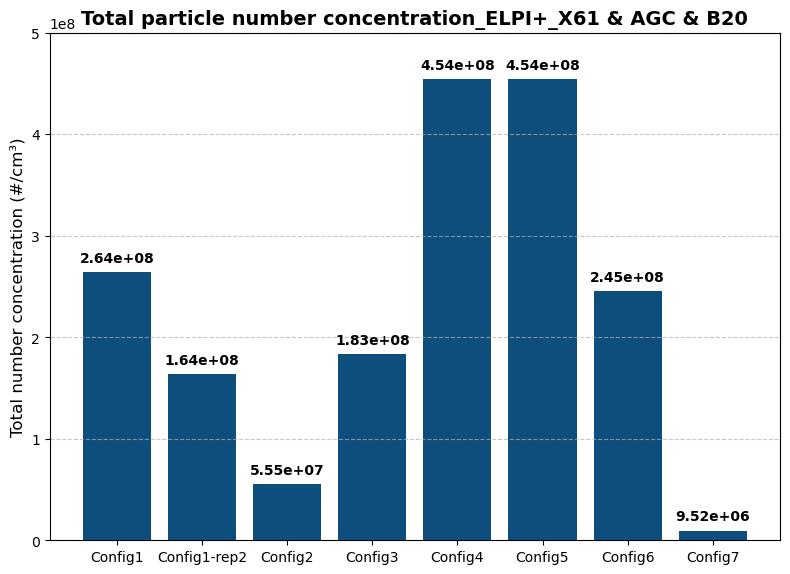

In [46]:
import matplotlib.pyplot as plt
import numpy as np

# Data
conditions = ['Config1', 'Config1-rep2', 'Config2', 'Config3', 'Config4', 'Config5', 'Config6','Config7']
total_concentration = np.array([2.64e8, 1.64e8, 5.55e7,  1.83e8, 4.54e8, 4.54e8, 2.45e8, 9.52e6])  # #/cm³

# Create bar chart with the exact blue from the reference graph
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(conditions, total_concentration, color="#0d4e7d")  # Matplotlib default blue

# Labels, title, grid
ax.set_ylabel('Total number concentration (#/cm³)', fontsize=12)
ax.set_title('Total particle number concentration_ELPI+_X61 & AGC & B20', fontsize=14)
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.set_ylim(0, 5e8)

# Annotate each bar with its concentration value
for bar, conc in zip(bars, total_concentration):
    height = bar.get_height()
    ax.annotate(f'{conc:.2e}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5),
                textcoords="offset points",
                ha='center', va='bottom',
                fontsize=10, fontweight='bold')

# Scientific notation on y-axis
ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))

plt.tight_layout()
plt.show()

X61

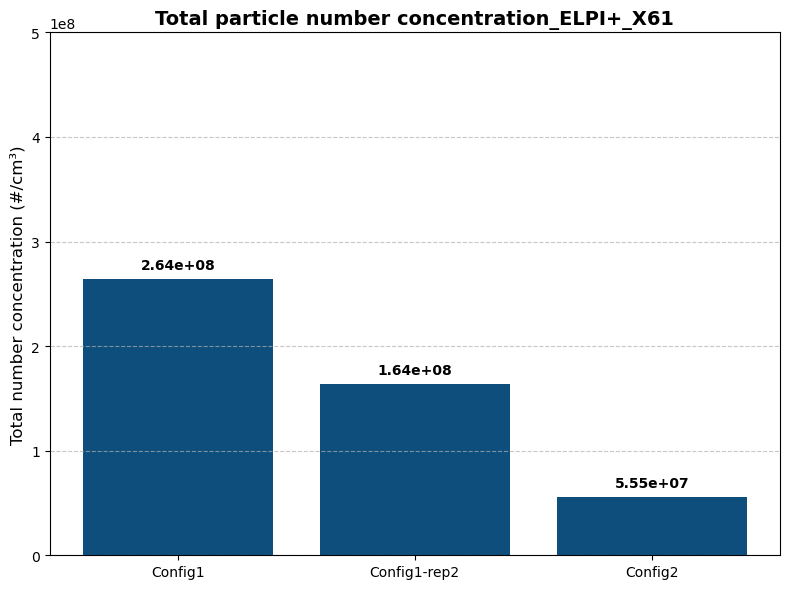

In [47]:
import matplotlib.pyplot as plt
import numpy as np

# Data
conditions = ['Config1', 'Config1-rep2', 'Config2']
total_concentration = np.array([2.64e8, 1.64e8, 5.55e7])  # #/cm³

# Create bar chart with the exact blue from the reference graph
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(conditions, total_concentration, color="#0d4e7d")  # Matplotlib default blue

# Labels, title, grid
ax.set_ylabel('Total number concentration (#/cm³)', fontsize=12)
ax.set_title('Total particle number concentration_ELPI+_X61', fontsize=14)
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.set_ylim(0, 5e8)

# Annotate each bar with its concentration value
for bar, conc in zip(bars, total_concentration):
    height = bar.get_height()
    ax.annotate(f'{conc:.2e}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5),
                textcoords="offset points",
                ha='center', va='bottom',
                fontsize=10, fontweight='bold')

# Scientific notation on y-axis
ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))

plt.tight_layout()
plt.show()

AGC

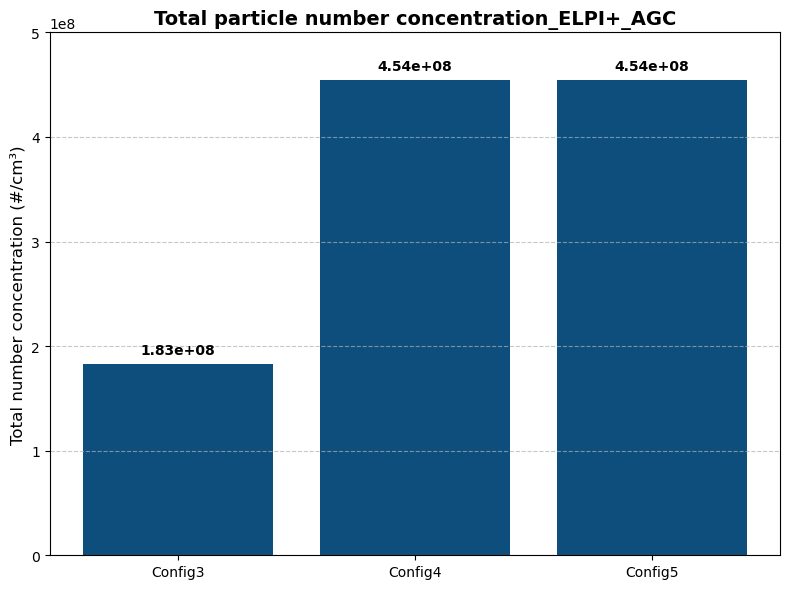

In [48]:
import matplotlib.pyplot as plt
import numpy as np

# Data
conditions = ['Config3', 'Config4', 'Config5']
total_concentration = np.array([1.83e8, 4.54e8, 4.54e8])  # #/cm³

# Create bar chart with the exact blue from the reference graph
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(conditions, total_concentration, color="#0d4e7d")  # Matplotlib default blue

# Labels, title, grid
ax.set_ylabel('Total number concentration (#/cm³)', fontsize=12)
ax.set_title('Total particle number concentration_ELPI+_AGC', fontsize=14)
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.set_ylim(0, 5e8)

# Annotate each bar with its concentration value
for bar, conc in zip(bars, total_concentration):
    height = bar.get_height()
    ax.annotate(f'{conc:.2e}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5),
                textcoords="offset points",
                ha='center', va='bottom',
                fontsize=10, fontweight='bold')

# Scientific notation on y-axis
ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))

plt.tight_layout()
plt.show()

B20

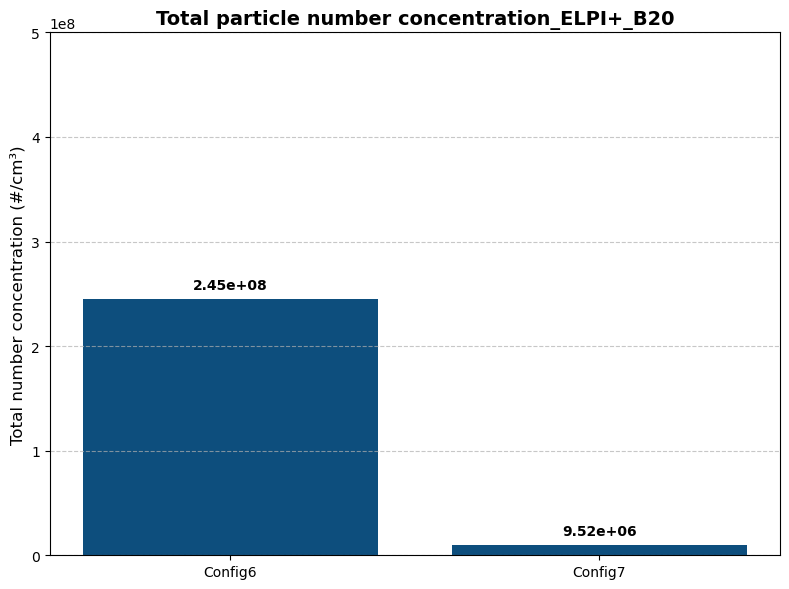

In [49]:
import matplotlib.pyplot as plt
import numpy as np

# Data
conditions = ['Config6', 'Config7']
total_concentration = np.array([2.45e8, 9.52e6])  # #/cm³

# Create bar chart with the exact blue from the reference graph
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(conditions, total_concentration, color="#0d4e7d")  # Matplotlib default blue

# Labels, title, grid
ax.set_ylabel('Total number concentration (#/cm³)', fontsize=12)
ax.set_title('Total particle number concentration_ELPI+_B20', fontsize=14)
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.set_ylim(0, 5e8)

# Annotate each bar with its concentration value
for bar, conc in zip(bars, total_concentration):
    height = bar.get_height()
    ax.annotate(f'{conc:.2e}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5),
                textcoords="offset points",
                ha='center', va='bottom',
                fontsize=10, fontweight='bold')

# Scientific notation on y-axis
ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))

plt.tight_layout()
plt.show()

PM0.1 and PM1 and PM2.5 and PM10 for all configs

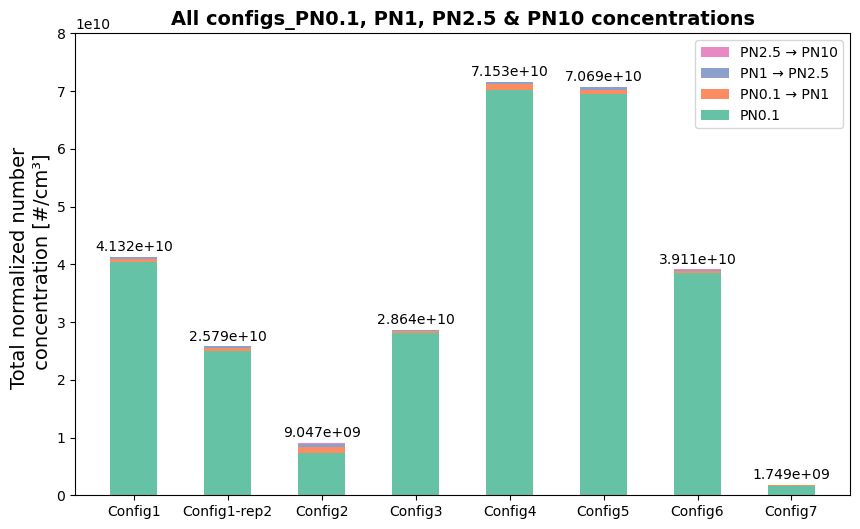

In [70]:
# Données
categories = ['Config1', 'Config1-rep2', 'Config2', 'Config3', 'Config4', 'Config5', 'Config6', 'Config7']

# Segments pour chaque configuration
seg_PM0_1 = [4.032e+10, 2.499e+10, 7.332e+09, 2.811e10, 7.024E10, 6.950e10, 3.841E10, 1.678E9]  # PM0.1 uniquement
seg_PM1   = [6.8e+08, 5.4e+08, 9.43e+08, (2.838e10 - 2.811e10), (7.116e10 - 7.024e10), (7.025e10 - 6.950e10), (3.889E10 - 3.841E10), (1.719E9 - 1.678E9)]  # PM0.1 → PM1
seg_PM2_5 = [2.9e+08, 2.4e+08, 6.45e+08, (2.858e10 - 2.838e10), (7.150e10 - 7.116e10), (7.064e10 - 7.025e10), (3.909E10 - 3.889E10), (1.738E9 - 1.719E9)]  # PM1 → PM2.5
seg_PM10  = [3.0e+07, 2.0e+07, 1.27e+08, (2.864e10 - 2.858e10), (7.153e10 - 7.150e10), (7.069e10 - 7.064e10), (3.911E10 - 3.909E10), (1.749E9 - 1.738E9)]  # PM2.5 → PM10 
width = 0.5

# Positions des barres sur l'axe x
x = np.arange(len(categories))  # [0,1,2,3,4] -> length 5

colors = ['#66c2a5', '#fc8d62', '#8da0cb', '#e78ac3']

fig, ax = plt.subplots(figsize=(10, 6))

# Barres empilées
bar_PM0_1 = ax.bar(x, seg_PM0_1, width, color=colors[0], label='PN0.1')
bar_PM1   = ax.bar(x, seg_PM1, width, bottom=seg_PM0_1, color=colors[1], label='PN0.1 → PN1')
bar_PM2_5 = ax.bar(x, seg_PM2_5, width, bottom=np.array(seg_PM0_1)+np.array(seg_PM1), color=colors[2], label='PN1 → PN2.5')
bar_PM10  = ax.bar(x, seg_PM10, width, bottom=np.array(seg_PM0_1)+np.array(seg_PM1)+np.array(seg_PM2_5), color=colors[3], label='PN2.5 → PN10')

# Ajouter les totaux au-dessus de chaque barre
totaux = np.array(seg_PM0_1) + np.array(seg_PM1) + np.array(seg_PM2_5) + np.array(seg_PM10)
for i, total in enumerate(totaux):
    ax.text(x[i], total + 0.5e+9, f'{total:.3e}', ha='center', va='bottom', fontsize=10)

# Titre et labels
ax.set_title('All configs_PN0.1, PN1, PN2.5 & PN10 concentrations', fontsize=14)
ax.set_ylabel('Total normalized number \n concentration [#/cm³]')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylim(0, 8E10)

# Légende dans l’ordre PM10 → PM2.5 → PM1 → PM0.1
handles, labels = ax.get_legend_handles_labels()
order = [3, 2, 1, 0]
ax.legend([handles[i] for i in order], [labels[i] for i in order])

plt.show()

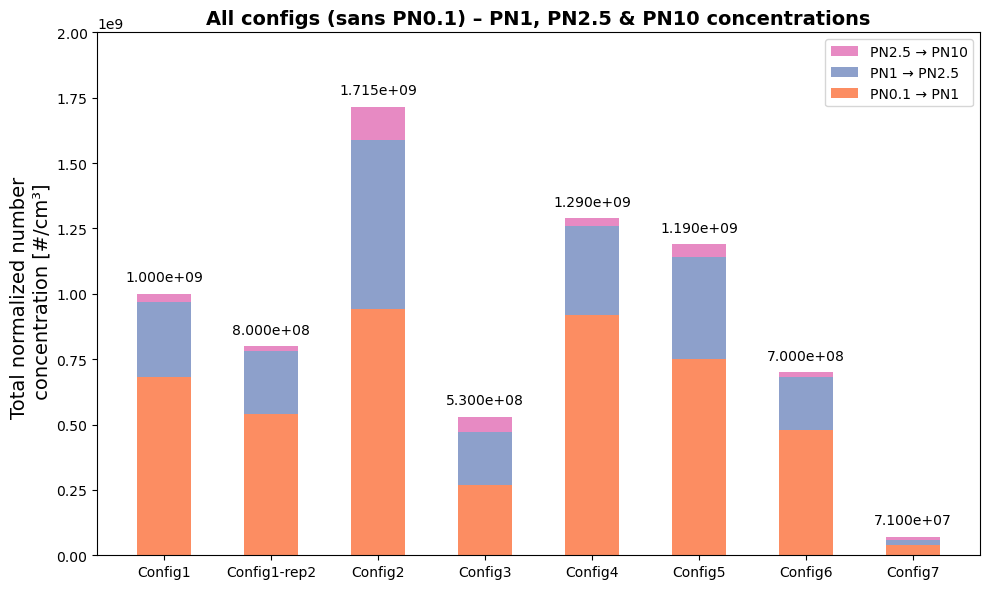

In [80]:
import numpy as np
import matplotlib.pyplot as plt

# Données
categories = ['Config1', 'Config1-rep2', 'Config2', 'Config3', 'Config4', 'Config5', 'Config6', 'Config7']

seg_PM0_1 = [4.032e+10, 2.499e+10, 7.332e+09, 2.811e10, 7.024E10, 6.950e10, 3.841E10, 1.678E9]
seg_PM1   = [6.8e+08, 5.4e+08, 9.43e+08, (2.838e10 - 2.811e10), (7.116e10 - 7.024e10), (7.025e10 - 6.950e10), (3.889E10 - 3.841E10), (1.719E9 - 1.678E9)]
seg_PM2_5 = [2.9e+08, 2.4e+08, 6.45e+08, (2.858e10 - 2.838e10), (7.150e10 - 7.116e10), (7.064e10 - 7.025e10), (3.909E10 - 3.889E10), (1.738E9 - 1.719E9)]
seg_PM10  = [3.0e+07, 2.0e+07, 1.27e+08, (2.864e10 - 2.858e10), (7.153e10 - 7.150e10), (7.069e10 - 7.064e10), (3.911E10 - 3.909E10), (1.749E9 - 1.738E9)]

width = 0.5
x = np.arange(len(categories))
colors = ['#fc8d62', '#8da0cb', '#e78ac3']   # orange, bleu, rose

fig, ax = plt.subplots(figsize=(10, 6))

# Barres empilées (sans PN0.1)
bar_PM1   = ax.bar(x, seg_PM1, width, color=colors[0], label='PN0.1 → PN1')
bar_PM2_5 = ax.bar(x, seg_PM2_5, width, bottom=seg_PM1, color=colors[1], label='PN1 → PN2.5')
bar_PM10  = ax.bar(x, seg_PM10, width, bottom=np.array(seg_PM1)+np.array(seg_PM2_5),
                   color=colors[2], label='PN2.5 → PN10')

# Totaux sans PN0.1
totaux = np.array(seg_PM1) + np.array(seg_PM2_5) + np.array(seg_PM10)

# Affichage des totaux avec un décalage relatif (2% de la hauteur de l'axe)
ylim = ax.get_ylim()
for i, total in enumerate(totaux):
    offset = 0.02 * ylim[1]   # 2% de la hauteur totale du graphique
    ax.text(x[i], total + offset, f'{total:.3e}',
            ha='center', va='bottom', fontsize=10, color='black')

# Titre et labels
ax.set_title('All configs (sans PN0.1) – PN1, PN2.5 & PN10 concentrations', fontsize=14)
ax.set_ylabel('Total normalized number \n concentration [#/cm³]')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylim(0, 2E9)   # Ajustez si nécessaire

# Légende (ordre PN10 → PN2.5 → PN1)
handles, labels = ax.get_legend_handles_labels()
ax.legend([handles[2], handles[1], handles[0]], [labels[2], labels[1], labels[0]])

plt.tight_layout()
plt.show()

X61

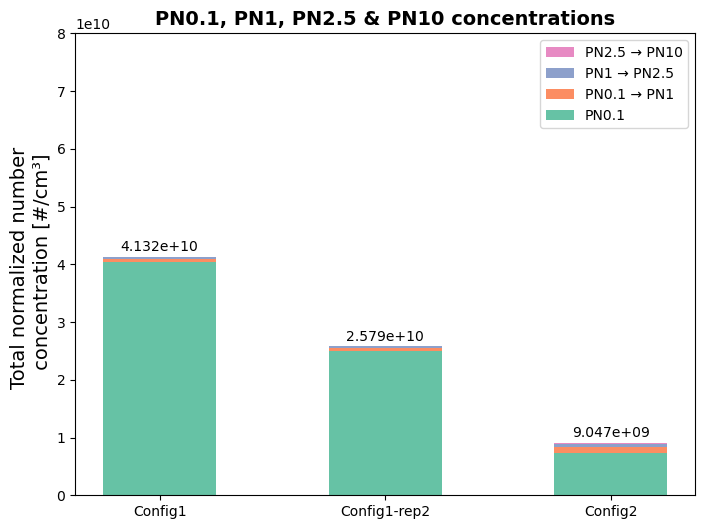

In [81]:
# Données
categories = ['Config1', 'Config1-rep2', 'Config2']

# Segments pour chaque configuration
seg_PM0_1 = [4.032e+10, 2.499e+10, 7.332e+09]  # PM0.1 uniquement
seg_PM1   = [6.8e+08, 5.4e+08, 9.43e+08]  # PM0.1 → PM1
seg_PM2_5 = [2.9e+08, 2.4e+08, 6.45e+08]  # PM1 → PM2.5
seg_PM10  = [3.0e+07, 2.0e+07, 1.27e+08]  # PM2.5 → PM10 
width = 0.5

# Positions des barres sur l'axe x
x = np.arange(len(categories))  # [0,1,2,3,4] -> length 5

colors = ['#66c2a5', '#fc8d62', '#8da0cb', '#e78ac3']

fig, ax = plt.subplots(figsize=(8, 6))

# Barres empilées
bar_PM0_1 = ax.bar(x, seg_PM0_1, width, color=colors[0], label='PN0.1')
bar_PM1   = ax.bar(x, seg_PM1, width, bottom=seg_PM0_1, color=colors[1], label='PN0.1 → PN1')
bar_PM2_5 = ax.bar(x, seg_PM2_5, width, bottom=np.array(seg_PM0_1)+np.array(seg_PM1), color=colors[2], label='PN1 → PN2.5')
bar_PM10  = ax.bar(x, seg_PM10, width, bottom=np.array(seg_PM0_1)+np.array(seg_PM1)+np.array(seg_PM2_5), color=colors[3], label='PN2.5 → PN10')

# Ajouter les totaux au-dessus de chaque barre
totaux = np.array(seg_PM0_1) + np.array(seg_PM1) + np.array(seg_PM2_5) + np.array(seg_PM10)
for i, total in enumerate(totaux):
    ax.text(x[i], total + 0.5e+9, f'{total:.3e}', ha='center', va='bottom', fontsize=10)

# Titre et labels
ax.set_title('PN0.1, PN1, PN2.5 & PN10 concentrations', fontsize=14)
ax.set_ylabel('Total normalized number \n concentration [#/cm³]')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylim(0, 8E10)

# Légende dans l’ordre PM10 → PM2.5 → PM1 → PM0.1
handles, labels = ax.get_legend_handles_labels()
order = [3, 2, 1, 0]
ax.legend([handles[i] for i in order], [labels[i] for i in order])

plt.show()

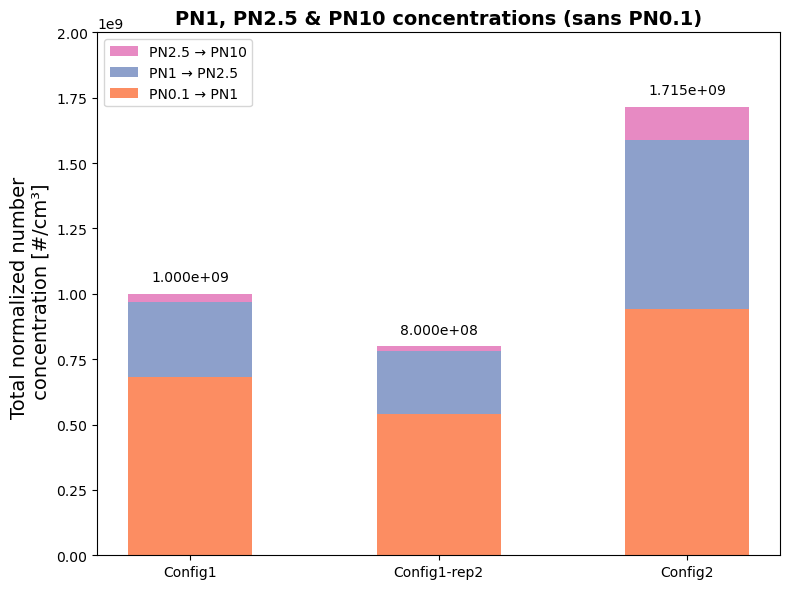

In [82]:
import numpy as np
import matplotlib.pyplot as plt

# Données pour les 3 configurations
categories = ['Config1', 'Config1-rep2', 'Config2']

seg_PM0_1 = [4.032e+10, 2.499e+10, 7.332e+09]  # non utilisé (PN0.1)
seg_PM1   = [6.8e+08, 5.4e+08, 9.43e+08]       # PN0.1 → PN1
seg_PM2_5 = [2.9e+08, 2.4e+08, 6.45e+08]       # PN1 → PN2.5
seg_PM10  = [3.0e+07, 2.0e+07, 1.27e+08]       # PN2.5 → PN10

width = 0.5
x = np.arange(len(categories))

# Couleurs (on garde les trois couleurs pour les trois segments, sans le vert de PN0.1)
colors = ['#fc8d62', '#8da0cb', '#e78ac3']   # orange, bleu, rose

fig, ax = plt.subplots(figsize=(8, 6))

# Barres empilées : on commence par PN0.1→PN1 en bas
bar_PM1   = ax.bar(x, seg_PM1, width, color=colors[0], label='PN0.1 → PN1')
bar_PM2_5 = ax.bar(x, seg_PM2_5, width, bottom=seg_PM1, color=colors[1], label='PN1 → PN2.5')
bar_PM10  = ax.bar(x, seg_PM10, width,
                   bottom=np.array(seg_PM1) + np.array(seg_PM2_5),
                   color=colors[2], label='PN2.5 → PN10')

# Totaux sans PN0.1
totaux = np.array(seg_PM1) + np.array(seg_PM2_5) + np.array(seg_PM10)

# Afficher les totaux au-dessus des barres avec un décalage relatif
ylim = ax.get_ylim()
for i, total in enumerate(totaux):
    offset = 0.02 * ylim[1]   # 2% de la hauteur de l'axe
    ax.text(x[i], total + offset, f'{total:.3e}',
            ha='center', va='bottom', fontsize=10, color='black')

# Titre et labels (adapté)
ax.set_title('PN1, PN2.5 & PN10 concentrations (sans PN0.1)', fontsize=14)
ax.set_ylabel('Total normalized number \n concentration [#/cm³]')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylim(0, 2E9)   # échelle ajustée (le max est ~1.715e9)

# Légende dans l'ordre PN10 → PN2.5 → PN1
handles, labels = ax.get_legend_handles_labels()
order = [2, 1, 0]   # PN10, PN2.5, PN1
ax.legend([handles[i] for i in order], [labels[i] for i in order])

plt.tight_layout()
plt.show()

AGC

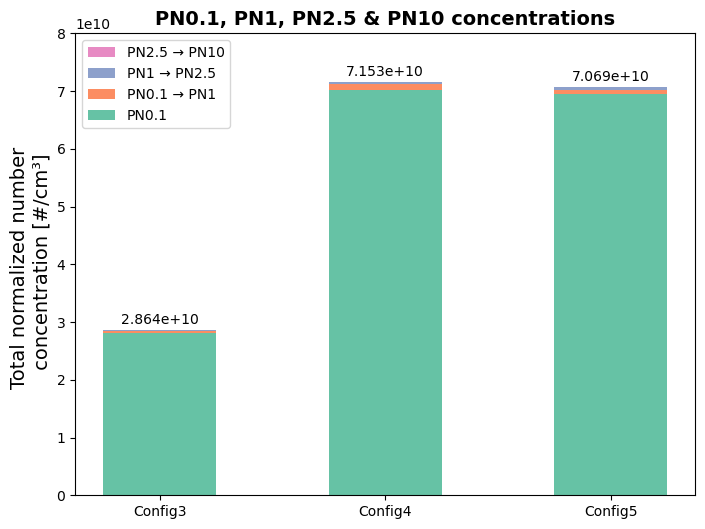

In [83]:
# Données
categories = ['Config3', 'Config4', 'Config5']

# Segments pour chaque configuration
seg_PM0_1 = [2.811e10, 7.024E10, 6.950e10]  # PM0.1 uniquement
seg_PM1   = [(2.838e10 - 2.811e10), (7.116e10 - 7.024e10), (7.025e10 - 6.950e10)]  # PM0.1 → PM1
seg_PM2_5 = [(2.858e10 - 2.838e10), (7.150e10 - 7.116e10), (7.064e10 - 7.025e10)]  # PM1 → PM2.5
seg_PM10  = [(2.864e10 - 2.858e10), (7.153e10 - 7.150e10), (7.069e10 - 7.064e10)]  # PM2.5 → PM10 
width = 0.5

# Positions des barres sur l'axe x
x = np.arange(len(categories))  # [0,1,2,3,4] -> length 5

colors = ['#66c2a5', '#fc8d62', '#8da0cb', '#e78ac3']

fig, ax = plt.subplots(figsize=(8, 6))

# Barres empilées
bar_PM0_1 = ax.bar(x, seg_PM0_1, width, color=colors[0], label='PN0.1')
bar_PM1   = ax.bar(x, seg_PM1, width, bottom=seg_PM0_1, color=colors[1], label='PN0.1 → PN1')
bar_PM2_5 = ax.bar(x, seg_PM2_5, width, bottom=np.array(seg_PM0_1)+np.array(seg_PM1), color=colors[2], label='PN1 → PN2.5')
bar_PM10  = ax.bar(x, seg_PM10, width, bottom=np.array(seg_PM0_1)+np.array(seg_PM1)+np.array(seg_PM2_5), color=colors[3], label='PN2.5 → PN10')

# Ajouter les totaux au-dessus de chaque barre
totaux = np.array(seg_PM0_1) + np.array(seg_PM1) + np.array(seg_PM2_5) + np.array(seg_PM10)
for i, total in enumerate(totaux):
    ax.text(x[i], total + 0.5e+9, f'{total:.3e}', ha='center', va='bottom', fontsize=10)

# Titre et labels
ax.set_title('PN0.1, PN1, PN2.5 & PN10 concentrations', fontsize=14)
ax.set_ylabel('Total normalized number \n concentration [#/cm³]')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylim(0, 8E10)

# Légende dans l’ordre PM10 → PM2.5 → PM1 → PM0.1
handles, labels = ax.get_legend_handles_labels()
order = [3, 2, 1, 0]
ax.legend([handles[i] for i in order], [labels[i] for i in order])

plt.show()

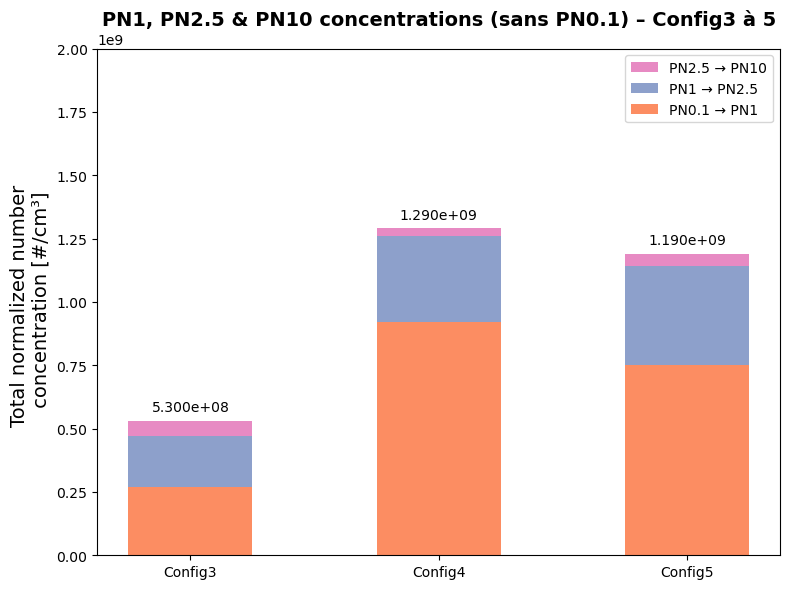

In [84]:
import numpy as np
import matplotlib.pyplot as plt

# Données pour Config3, Config4, Config5
categories = ['Config3', 'Config4', 'Config5']

seg_PM0_1 = [2.811e10, 7.024E10, 6.950e10]  # non utilisé (PN0.1)
seg_PM1   = [(2.838e10 - 2.811e10), (7.116e10 - 7.024e10), (7.025e10 - 6.950e10)]  # PN0.1 → PN1
seg_PM2_5 = [(2.858e10 - 2.838e10), (7.150e10 - 7.116e10), (7.064e10 - 7.025e10)]  # PN1 → PN2.5
seg_PM10  = [(2.864e10 - 2.858e10), (7.153e10 - 7.150e10), (7.069e10 - 7.064e10)]  # PN2.5 → PN10

width = 0.5
x = np.arange(len(categories))

# Couleurs pour les trois segments (on retire le vert de PN0.1)
colors = ['#fc8d62', '#8da0cb', '#e78ac3']   # orange, bleu, rose

fig, ax = plt.subplots(figsize=(8, 6))

# Barres empilées sans PN0.1 : PN0.1→PN1 en bas
bar_PM1   = ax.bar(x, seg_PM1, width, color=colors[0], label='PN0.1 → PN1')
bar_PM2_5 = ax.bar(x, seg_PM2_5, width, bottom=seg_PM1, color=colors[1], label='PN1 → PN2.5')
bar_PM10  = ax.bar(x, seg_PM10, width,
                   bottom=np.array(seg_PM1) + np.array(seg_PM2_5),
                   color=colors[2], label='PN2.5 → PN10')

# Totaux sans PN0.1
totaux = np.array(seg_PM1) + np.array(seg_PM2_5) + np.array(seg_PM10)

# Affichage des totaux avec un décalage relatif (2% de la hauteur de l'axe)
ylim = ax.get_ylim()
for i, total in enumerate(totaux):
    offset = 0.02 * ylim[1]
    ax.text(x[i], total + offset, f'{total:.3e}',
            ha='center', va='bottom', fontsize=10, color='black')

# Titre et labels (modifiés pour refléter l'absence de PN0.1)
ax.set_title('PN1, PN2.5 & PN10 concentrations (sans PN0.1) – Config3 à 5', fontsize=14)
ax.set_ylabel('Total normalized number \n concentration [#/cm³]')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylim(0, 2E9)   # échelle adaptée (max ~1.19e9)

# Légende dans l'ordre PN10 → PN2.5 → PN1
handles, labels = ax.get_legend_handles_labels()
order = [2, 1, 0]   # PN10, PN2.5, PN1
ax.legend([handles[i] for i in order], [labels[i] for i in order])

plt.tight_layout()
plt.show()

B20

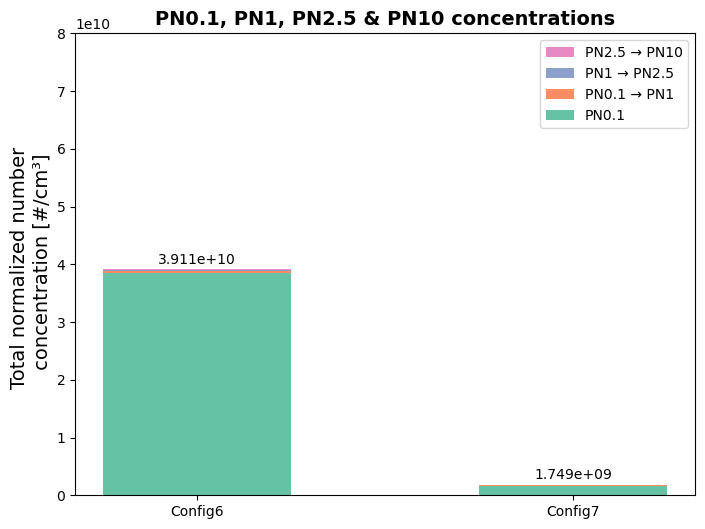

In [85]:
# Données
categories = ['Config6', 'Config7']

# Segments pour chaque configuration
seg_PM0_1 = [3.841E10, 1.678E9]  # PM0.1 uniquement
seg_PM1   = [(3.889E10 - 3.841E10), (1.719E9 - 1.678E9)]  # PM0.1 → PM1
seg_PM2_5 = [(3.909E10 - 3.889E10), (1.738E9 - 1.719E9)]  # PM1 → PM2.5
seg_PM10  = [(3.911E10 - 3.909E10), (1.749E9 - 1.738E9)]  # PM2.5 → PM10 
width = 0.5

# Positions des barres sur l'axe x
x = np.arange(len(categories))  # [0,1,2,3,4] -> length 5

colors = ['#66c2a5', '#fc8d62', '#8da0cb', '#e78ac3']

fig, ax = plt.subplots(figsize=(8, 6))

# Barres empilées
bar_PM0_1 = ax.bar(x, seg_PM0_1, width, color=colors[0], label='PN0.1')
bar_PM1   = ax.bar(x, seg_PM1, width, bottom=seg_PM0_1, color=colors[1], label='PN0.1 → PN1')
bar_PM2_5 = ax.bar(x, seg_PM2_5, width, bottom=np.array(seg_PM0_1)+np.array(seg_PM1), color=colors[2], label='PN1 → PN2.5')
bar_PM10  = ax.bar(x, seg_PM10, width, bottom=np.array(seg_PM0_1)+np.array(seg_PM1)+np.array(seg_PM2_5), color=colors[3], label='PN2.5 → PN10')

# Ajouter les totaux au-dessus de chaque barre
totaux = np.array(seg_PM0_1) + np.array(seg_PM1) + np.array(seg_PM2_5) + np.array(seg_PM10)
for i, total in enumerate(totaux):
    ax.text(x[i], total + 0.5e+9, f'{total:.3e}', ha='center', va='bottom', fontsize=10)

# Titre et labels
ax.set_title('PN0.1, PN1, PN2.5 & PN10 concentrations', fontsize=14)
ax.set_ylabel('Total normalized number \n concentration [#/cm³]')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylim(0, 8E10)

# Légende dans l’ordre PM10 → PM2.5 → PM1 → PM0.1
handles, labels = ax.get_legend_handles_labels()
order = [3, 2, 1, 0]
ax.legend([handles[i] for i in order], [labels[i] for i in order])

plt.show()

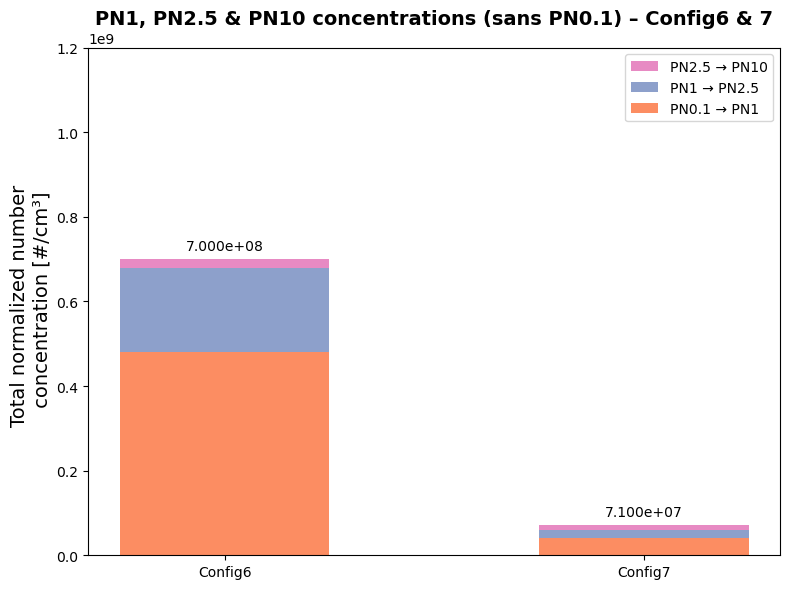

In [86]:
import numpy as np
import matplotlib.pyplot as plt

# Données pour Config6 et Config7
categories = ['Config6', 'Config7']

seg_PM0_1 = [3.841E10, 1.678E9]  # non utilisé (PN0.1)
seg_PM1   = [(3.889E10 - 3.841E10), (1.719E9 - 1.678E9)]  # PN0.1 → PN1
seg_PM2_5 = [(3.909E10 - 3.889E10), (1.738E9 - 1.719E9)]  # PN1 → PN2.5
seg_PM10  = [(3.911E10 - 3.909E10), (1.749E9 - 1.738E9)]  # PN2.5 → PN10

width = 0.5
x = np.arange(len(categories))

# Couleurs pour les trois segments (on retire le vert de PN0.1)
colors = ['#fc8d62', '#8da0cb', '#e78ac3']   # orange, bleu, rose

fig, ax = plt.subplots(figsize=(8, 6))

# Barres empilées sans PN0.1 : PN0.1→PN1 en bas
bar_PM1   = ax.bar(x, seg_PM1, width, color=colors[0], label='PN0.1 → PN1')
bar_PM2_5 = ax.bar(x, seg_PM2_5, width, bottom=seg_PM1, color=colors[1], label='PN1 → PN2.5')
bar_PM10  = ax.bar(x, seg_PM10, width,
                   bottom=np.array(seg_PM1) + np.array(seg_PM2_5),
                   color=colors[2], label='PN2.5 → PN10')

# Totaux sans PN0.1
totaux = np.array(seg_PM1) + np.array(seg_PM2_5) + np.array(seg_PM10)

# Affichage des totaux avec un décalage relatif (2% de la hauteur de l'axe)
ylim = ax.get_ylim()
for i, total in enumerate(totaux):
    offset = 0.02 * ylim[1]   # 2% de la hauteur totale du graphique
    ax.text(x[i], total + offset, f'{total:.3e}',
            ha='center', va='bottom', fontsize=10, color='black')

# Titre et labels (modifiés pour refléter l'absence de PN0.1)
ax.set_title('PN1, PN2.5 & PN10 concentrations (sans PN0.1) – Config6 & 7', fontsize=14)
ax.set_ylabel('Total normalized number \n concentration [#/cm³]')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylim(0, 1.2E9)   # échelle adaptée (max ~9.8e8)

# Légende dans l'ordre PN10 → PN2.5 → PN1
handles, labels = ax.get_legend_handles_labels()
order = [2, 1, 0]   # PN10, PN2.5, PN1
ax.legend([handles[i] for i in order], [labels[i] for i in order])

plt.tight_layout()
plt.show()

PM1 and PM2.5 and PM10 for all configs

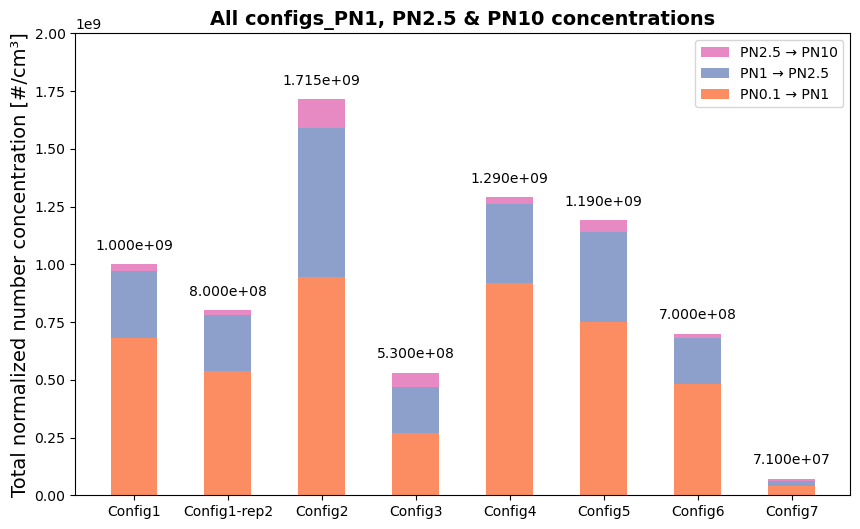

In [87]:
import matplotlib.pyplot as plt
import numpy as np

# Données
categories = ['Config1', 'Config1-rep2', 'Config2', 'Config3', 'Config4', 'Config5', 'Config6', 'Config7']

# Segments pour chaque configuration (sans PM0.1)
seg_PM1   = [6.8e+08, 5.4e+08, 9.43e+08, (2.838e10 - 2.811e10), (7.116e10 - 7.024e10), (7.025e10 - 6.950e10), (3.889E10 - 3.841E10), (1.719E9 - 1.678E9)]  # PM0.1 → PM1
seg_PM2_5 = [2.9e+08, 2.4e+08, 6.45e+08, (2.858e10 - 2.838e10), (7.150e10 - 7.116e10), (7.064e10 - 7.025e10), (3.909E10 - 3.889E10), (1.738E9 - 1.719E9)]  # PM1 → PM2.5
seg_PM10  = [3.0e+07, 2.0e+07, 1.27e+08, (2.864e10 - 2.858e10), (7.153e10 - 7.150e10), (7.069e10 - 7.064e10), (3.911E10 - 3.909E10), (1.749E9 - 1.738E9)]  # PM2.5 → PM10

width = 0.5
x = np.arange(len(categories))

# Couleurs (sans PM0.1)
colors = ['#fc8d62', '#8da0cb', '#e78ac3']  # PM1, PM2.5, PM10

fig, ax = plt.subplots(figsize=(10, 6))

# Barres empilées
bar_PM1   = ax.bar(x, seg_PM1, width, color=colors[0], label='PN0.1 → PN1')
bar_PM2_5 = ax.bar(x, seg_PM2_5, width, bottom=seg_PM1, color=colors[1], label='PN1 → PN2.5')
bar_PM10  = ax.bar(x, seg_PM10, width, bottom=np.array(seg_PM1)+np.array(seg_PM2_5), color=colors[2], label='PN2.5 → PN10')

# Totaux sans PM0.1
totaux = np.array(seg_PM1) + np.array(seg_PM2_5) + np.array(seg_PM10)
for i, total in enumerate(totaux):
    ax.text(x[i], total + 0.05e+9, f'{total:.3e}', ha='center', va='bottom', fontsize=10)

# Titre et labels
ax.set_title('All configs_PN1, PN2.5 & PN10 concentrations', fontsize=14)
ax.set_ylabel('Total normalized number concentration [#/cm³]')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylim(0, 2e9)  # limite automatique

# Légende dans l’ordre PM10 → PM2.5 → PM1
handles, labels = ax.get_legend_handles_labels()
order = [2, 1, 0]  # PM10, PM2.5, PM1
ax.legend([handles[i] for i in order], [labels[i] for i in order])

plt.show()

X61

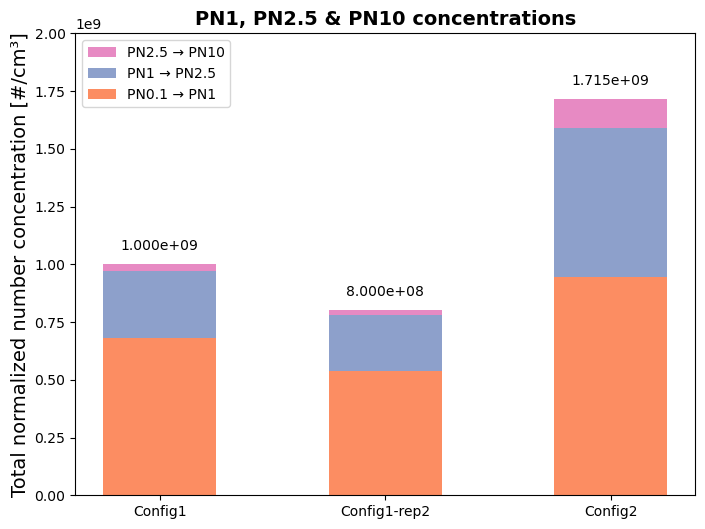

In [88]:
import matplotlib.pyplot as plt
import numpy as np

# Données
categories = ['Config1', 'Config1-rep2', 'Config2']

# Segments pour chaque configuration (sans PM0.1)
seg_PM1   = [6.8e+08, 5.4e+08, 9.43e+08]   # PM0.1 → PM1
seg_PM2_5 = [2.9e+08, 2.4e+08, 6.45e+08]  # PM1 → PM2.5
seg_PM10  = [3.0e+07, 2.0e+07, 1.27e+08]  # PM2.5 → PM10

width = 0.5
x = np.arange(len(categories))

# Couleurs (ajustées, plus de PM0.1)
colors = ['#fc8d62', '#8da0cb', '#e78ac3']  # PM1, PM2.5, PM10

fig, ax = plt.subplots(figsize=(8, 6))

# Barres empilées sans PM0.1
bar_PM1   = ax.bar(x, seg_PM1, width, color=colors[0], label='PN0.1 → PN1')
bar_PM2_5 = ax.bar(x, seg_PM2_5, width, bottom=seg_PM1, color=colors[1], label='PN1 → PN2.5')
bar_PM10  = ax.bar(x, seg_PM10, width, bottom=np.array(seg_PM1)+np.array(seg_PM2_5), color=colors[2], label='PN2.5 → PN10')

# Totaux sans PM0.1
totaux = np.array(seg_PM1) + np.array(seg_PM2_5) + np.array(seg_PM10)
for i, total in enumerate(totaux):
    ax.text(x[i], total + 0.05e+9, f'{total:.3e}', ha='center', va='bottom', fontsize=10)

# Titre et labels
ax.set_title('PN1, PN2.5 & PN10 concentrations', fontsize=14)
ax.set_ylabel('Total normalized number concentration [#/cm³]')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylim(0, 2e9)  # limite ajustée automatiquement

# Légende dans l’ordre PM10 → PM2.5 → PM1
handles, labels = ax.get_legend_handles_labels()
order = [2, 1, 0]  # indices inverses : PM10, PM2.5, PM1
ax.legend([handles[i] for i in order], [labels[i] for i in order])

plt.show()

AGC

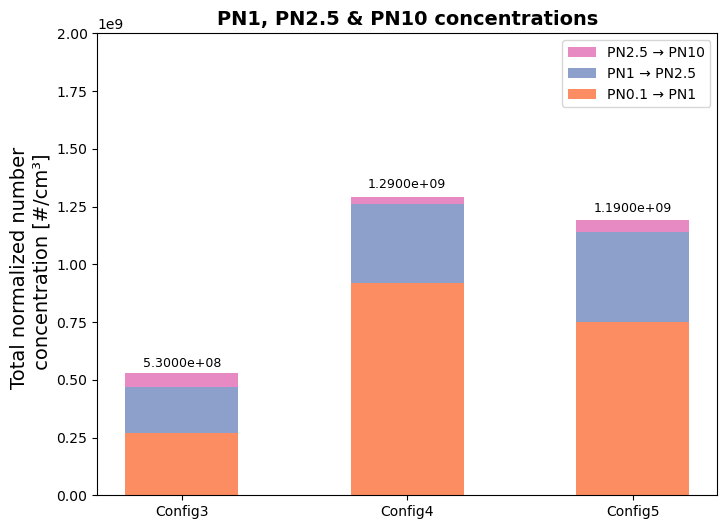

In [68]:
import numpy as np
import matplotlib.pyplot as plt

# Données
categories = ['Config3', 'Config4', 'Config5']

# Segments pour chaque configuration (sans PM0.1)
seg_PM1   = [(2.838e10 - 2.811e10), (7.116e10 - 7.024e10), (7.025e10 - 6.950e10)]  # PM0.1 → PM1
seg_PM2_5 = [(2.858e10 - 2.838e10), (7.150e10 - 7.116e10), (7.064e10 - 7.025e10)]  # PM1 → PM2.5
seg_PM10  = [(2.864e10 - 2.858e10), (7.153e10 - 7.150e10), (7.069e10 - 7.064e10)]  # PM2.5 → PM10 
width = 0.5
x = np.arange(len(categories))
colors = ['#fc8d62', '#8da0cb', '#e78ac3']  # colors for PM1, PM2.5, PM10

fig, ax = plt.subplots(figsize=(8, 6))

# Barres empilées (sans PM0.1)
bar_PM1   = ax.bar(x, seg_PM1, width, color=colors[0], label='PN0.1 → PN1')
bar_PM2_5 = ax.bar(x, seg_PM2_5, width, bottom=seg_PM1, color=colors[1], label='PN1 → PN2.5')
bar_PM10  = ax.bar(x, seg_PM10, width, bottom=np.array(seg_PM1)+np.array(seg_PM2_5), color=colors[2], label='PN2.5 → PN10')

# Ajouter les totaux au-dessus de chaque barre
totaux = np.array(seg_PM1) + np.array(seg_PM2_5) + np.array(seg_PM10)
for i, total in enumerate(totaux):
    offset = total * 0.02  # 2% above the bar
    ax.text(x[i], total + offset, f'{total:.4e}', ha='center', va='bottom', fontsize=9)

# Titre et labels
ax.set_title('PN1, PN2.5 & PN10 concentrations', fontsize=14)
ax.set_ylabel('Total normalized number \n concentration [#/cm³]')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylim(0, 2E9)

# Légende (ordre inverse: PM10, PM2.5, PM1)
handles, labels = ax.get_legend_handles_labels()
order = [2, 1, 0]  # now only 3 items
ax.legend([handles[i] for i in order], [labels[i] for i in order])

plt.show()

B20

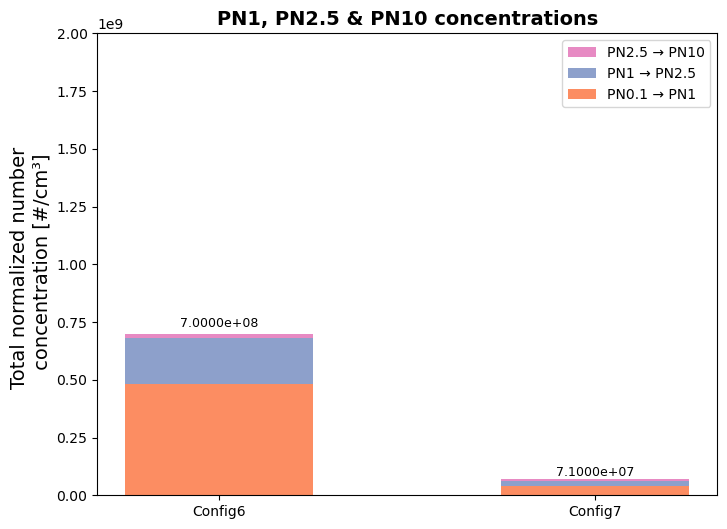

In [67]:
import numpy as np
import matplotlib.pyplot as plt

# Données
categories = ['Config6', 'Config7']

# Segments pour chaque configuration (sans PM0.1)
seg_PM1   = [(3.889E10 - 3.841E10), (1.719E9 - 1.678E9)]  # PM0.1 → PM1
seg_PM2_5 = [(3.909E10 - 3.889E10), (1.738E9 - 1.719E9)]  # PM1 → PM2.5
seg_PM10  = [(3.911E10 - 3.909E10), (1.749E9 - 1.738E9)]  # PM2.5 → PM10 
width = 0.5
x = np.arange(len(categories))
colors = ['#fc8d62', '#8da0cb', '#e78ac3']  # colors for PM1, PM2.5, PM10

fig, ax = plt.subplots(figsize=(8, 6))

# Barres empilées (sans PM0.1)
bar_PM1   = ax.bar(x, seg_PM1, width, color=colors[0], label='PN0.1 → PN1')
bar_PM2_5 = ax.bar(x, seg_PM2_5, width, bottom=seg_PM1, color=colors[1], label='PN1 → PN2.5')
bar_PM10  = ax.bar(x, seg_PM10, width, bottom=np.array(seg_PM1)+np.array(seg_PM2_5), color=colors[2], label='PN2.5 → PN10')

# Ajouter les totaux au-dessus de chaque barre
totaux = np.array(seg_PM1) + np.array(seg_PM2_5) + np.array(seg_PM10)
for i, total in enumerate(totaux):
    offset = total * 0.02  # 2% above the bar
    ax.text(x[i], total + offset, f'{total:.4e}', ha='center', va='bottom', fontsize=9)

# Titre et labels
ax.set_title('PN1, PN2.5 & PN10 concentrations', fontsize=14)
ax.set_ylabel('Total normalized number \n concentration [#/cm³]')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylim(0, 2E9)

# Légende (ordre inverse: PM10, PM2.5, PM1)
handles, labels = ax.get_legend_handles_labels()
order = [2, 1, 0]  # now only 3 items
ax.legend([handles[i] for i in order], [labels[i] for i in order])

plt.show()

Config1 vs Config6 

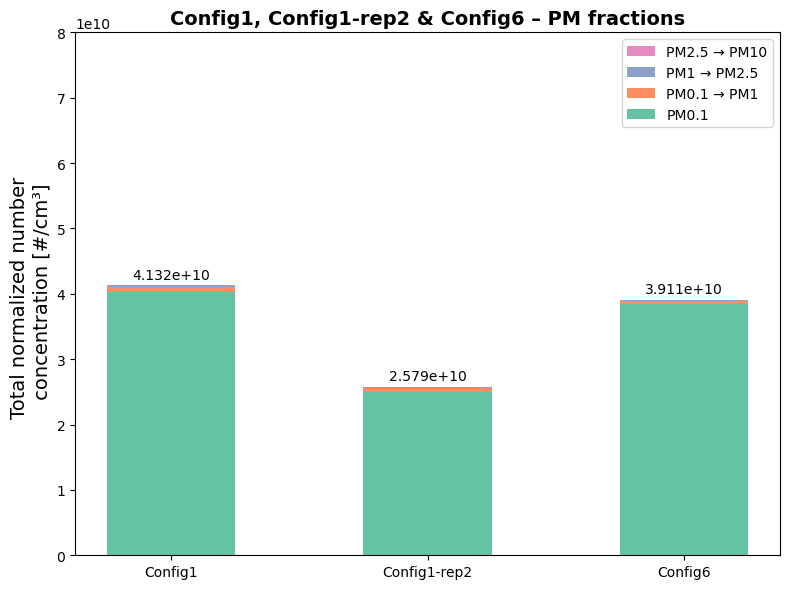

In [58]:
import numpy as np
import matplotlib.pyplot as plt

# Original data (indices: 0:Config1, 1:Config1-rep2, 2:Config2, 3:Config3, 4:Config4, 5:Config5, 6:Config6, 7:Config7)
seg_PM0_1 = [4.032e+10, 2.499e+10, 7.332e+09, 2.811e10, 7.024E10, 6.950e10, 3.841E10, 1.678E9]
seg_PM1   = [6.8e+08, 5.4e+08, 9.43e+08, (2.838e10 - 2.811e10), (7.116e10 - 7.024e10), (7.025e10 - 6.950e10), (3.889E10 - 3.841E10), (1.719E9 - 1.678E9)]
seg_PM2_5 = [2.9e+08, 2.4e+08, 6.45e+08, (2.858e10 - 2.838e10), (7.150e10 - 7.116e10), (7.064e10 - 7.025e10), (3.909E10 - 3.889E10), (1.738E9 - 1.719E9)]
seg_PM10  = [3.0e+07, 2.0e+07, 1.27e+08, (2.864e10 - 2.858e10), (7.153e10 - 7.150e10), (7.069e10 - 7.064e10), (3.911E10 - 3.909E10), (1.749E9 - 1.738E9)]

# Keep only Config1 (index 0), Config1-rep2 (index 1), and Config6 (index 6)
indices = [0, 1, 6]
categories = ['Config1', 'Config1-rep2', 'Config6']   # updated labels

seg_PM0_1 = [seg_PM0_1[i] for i in indices]
seg_PM1   = [seg_PM1[i]   for i in indices]
seg_PM2_5 = [seg_PM2_5[i] for i in indices]
seg_PM10  = [seg_PM10[i]  for i in indices]

width = 0.5
x = np.arange(len(categories))   # positions: 0,1,2

colors = ['#66c2a5', '#fc8d62', '#8da0cb', '#e78ac3']

fig, ax = plt.subplots(figsize=(8, 6))

# Stacked bars
bar_PM0_1 = ax.bar(x, seg_PM0_1, width, color=colors[0], label='PM0.1')
bar_PM1   = ax.bar(x, seg_PM1, width, bottom=seg_PM0_1, color=colors[1], label='PM0.1 → PM1')
bar_PM2_5 = ax.bar(x, seg_PM2_5, width, bottom=np.array(seg_PM0_1)+np.array(seg_PM1), color=colors[2], label='PM1 → PM2.5')
bar_PM10  = ax.bar(x, seg_PM10, width, bottom=np.array(seg_PM0_1)+np.array(seg_PM1)+np.array(seg_PM2_5), color=colors[3], label='PM2.5 → PM10')

# Totals above each bar
totaux = np.array(seg_PM0_1) + np.array(seg_PM1) + np.array(seg_PM2_5) + np.array(seg_PM10)
for i, total in enumerate(totaux):
    ax.text(x[i], total + 0.5e+9, f'{total:.3e}', ha='center', va='bottom', fontsize=10)

ax.set_title('Config1, Config1-rep2 & Config6 – PM fractions', fontsize=14)
ax.set_ylabel('Total normalized number \n concentration [#/cm³]')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylim(0, 8E10)

# Legend in desired order (PM10 → PM2.5 → PM1 → PM0.1)
handles, labels = ax.get_legend_handles_labels()
order = [3, 2, 1, 0]
ax.legend([handles[i] for i in order], [labels[i] for i in order])

plt.tight_layout()
plt.show()

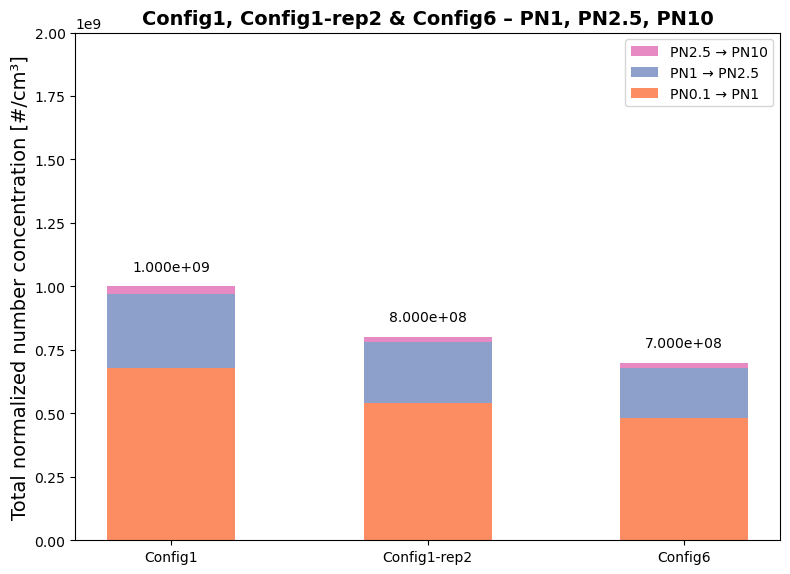

In [66]:
import matplotlib.pyplot as plt
import numpy as np

# Original data (indices: 0:Config1, 1:Config1-rep2, 2:Config2, 3:Config3, 4:Config4, 5:Config5, 6:Config6, 7:Config7)
seg_PM1   = [6.8e+08, 5.4e+08, 9.43e+08, (2.838e10 - 2.811e10), (7.116e10 - 7.024e10), (7.025e10 - 6.950e10), (3.889E10 - 3.841E10), (1.719E9 - 1.678E9)]
seg_PM2_5 = [2.9e+08, 2.4e+08, 6.45e+08, (2.858e10 - 2.838e10), (7.150e10 - 7.116e10), (7.064e10 - 7.025e10), (3.909E10 - 3.889E10), (1.738E9 - 1.719E9)]
seg_PM10  = [3.0e+07, 2.0e+07, 1.27e+08, (2.864e10 - 2.858e10), (7.153e10 - 7.150e10), (7.069e10 - 7.064e10), (3.911E10 - 3.909E10), (1.749E9 - 1.738E9)]

# Keep only Config1 (index 0), Config1-rep2 (index 1), and Config6 (index 6)
indices = [0, 1, 6]
categories = ['Config1', 'Config1-rep2', 'Config6']

seg_PM1   = [seg_PM1[i]   for i in indices]
seg_PM2_5 = [seg_PM2_5[i] for i in indices]
seg_PM10  = [seg_PM10[i]  for i in indices]

width = 0.5
x = np.arange(len(categories))

# Colors (without PM0.1)
colors = ['#fc8d62', '#8da0cb', '#e78ac3']  # PM1, PM2.5, PM10

fig, ax = plt.subplots(figsize=(8, 6))  # slightly smaller figure

# Stacked bars
bar_PM1   = ax.bar(x, seg_PM1, width, color=colors[0], label='PN0.1 → PN1')
bar_PM2_5 = ax.bar(x, seg_PM2_5, width, bottom=seg_PM1, color=colors[1], label='PN1 → PN2.5')
bar_PM10  = ax.bar(x, seg_PM10, width, bottom=np.array(seg_PM1)+np.array(seg_PM2_5), color=colors[2], label='PN2.5 → PN10')

# Totals (without PM0.1)
totaux = np.array(seg_PM1) + np.array(seg_PM2_5) + np.array(seg_PM10)
for i, total in enumerate(totaux):
    ax.text(x[i], total + 0.05e+9, f'{total:.3e}', ha='center', va='bottom', fontsize=10)

ax.set_title('Config1, Config1-rep2 & Config6 – PN1, PN2.5, PN10', fontsize=14)
ax.set_ylabel('Total normalized number concentration [#/cm³]')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylim(0, 2e9)  # adjust if needed; here 2e9 is fine for these three

# Legend in order PM10 → PM2.5 → PM1
handles, labels = ax.get_legend_handles_labels()
order = [2, 1, 0]  # PM10, PM2.5, PM1
ax.legend([handles[i] for i in order], [labels[i] for i in order])

plt.tight_layout()
plt.show()

Config2 vs Config3 

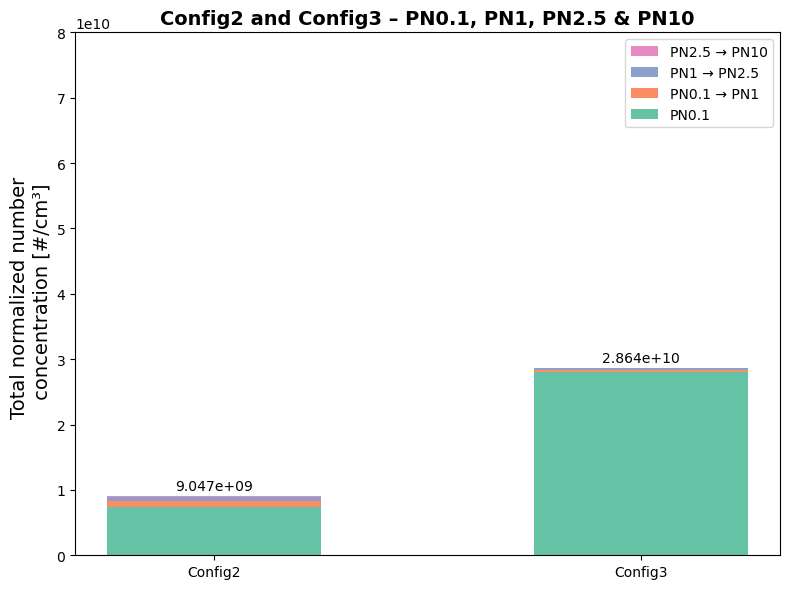

In [64]:
import matplotlib.pyplot as plt
import numpy as np

# Original data (indices: 0:Config1, 1:Config1-rep2, 2:Config2, 3:Config3, 4:Config4, 5:Config5, 6:Config6, 7:Config7)
seg_PM0_1 = [4.032e+10, 2.499e+10, 7.332e+09, 2.811e10, 7.024E10, 6.950e10, 3.841E10, 1.678E9]
seg_PM1   = [6.8e+08, 5.4e+08, 9.43e+08, (2.838e10 - 2.811e10), (7.116e10 - 7.024e10), (7.025e10 - 6.950e10), (3.889E10 - 3.841E10), (1.719E9 - 1.678E9)]
seg_PM2_5 = [2.9e+08, 2.4e+08, 6.45e+08, (2.858e10 - 2.838e10), (7.150e10 - 7.116e10), (7.064e10 - 7.025e10), (3.909E10 - 3.889E10), (1.738E9 - 1.719E9)]
seg_PM10  = [3.0e+07, 2.0e+07, 1.27e+08, (2.864e10 - 2.858e10), (7.153e10 - 7.150e10), (7.069e10 - 7.064e10), (3.911E10 - 3.909E10), (1.749E9 - 1.738E9)]

# Keep only Config2 (index 2) and Config3 (index 3)
indices = [2, 3]
categories = ['Config2', 'Config3']

seg_PM0_1 = [seg_PM0_1[i] for i in indices]
seg_PM1   = [seg_PM1[i]   for i in indices]
seg_PM2_5 = [seg_PM2_5[i] for i in indices]
seg_PM10  = [seg_PM10[i]  for i in indices]

width = 0.5
x = np.arange(len(categories))

colors = ['#66c2a5', '#fc8d62', '#8da0cb', '#e78ac3']

fig, ax = plt.subplots(figsize=(8, 6))

# Stacked bars
bar_PM0_1 = ax.bar(x, seg_PM0_1, width, color=colors[0], label='PN0.1')
bar_PM1   = ax.bar(x, seg_PM1, width, bottom=seg_PM0_1, color=colors[1], label='PN0.1 → PN1')
bar_PM2_5 = ax.bar(x, seg_PM2_5, width, bottom=np.array(seg_PM0_1)+np.array(seg_PM1), color=colors[2], label='PN1 → PN2.5')
bar_PM10  = ax.bar(x, seg_PM10, width, bottom=np.array(seg_PM0_1)+np.array(seg_PM1)+np.array(seg_PM2_5), color=colors[3], label='PN2.5 → PN10')

# Totals above each bar
totaux = np.array(seg_PM0_1) + np.array(seg_PM1) + np.array(seg_PM2_5) + np.array(seg_PM10)
for i, total in enumerate(totaux):
    ax.text(x[i], total + 0.5e+9, f'{total:.3e}', ha='center', va='bottom', fontsize=10)

ax.set_title('Config2 and Config3 – PN0.1, PN1, PN2.5 & PN10', fontsize=14)
ax.set_ylabel('Total normalized number \n concentration [#/cm³]')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylim(0, 8E10)   # y-limit still appropriate (Config2 total ~7.95e9? Actually check: Config2: 7.332e9+9.43e8+6.45e8+1.27e8 ≈ 8.08e9, within 8e10, so fine)

# Legend in order PM10 → PM2.5 → PM1 → PM0.1
handles, labels = ax.get_legend_handles_labels()
order = [3, 2, 1, 0]
ax.legend([handles[i] for i in order], [labels[i] for i in order])

plt.tight_layout()
plt.show()

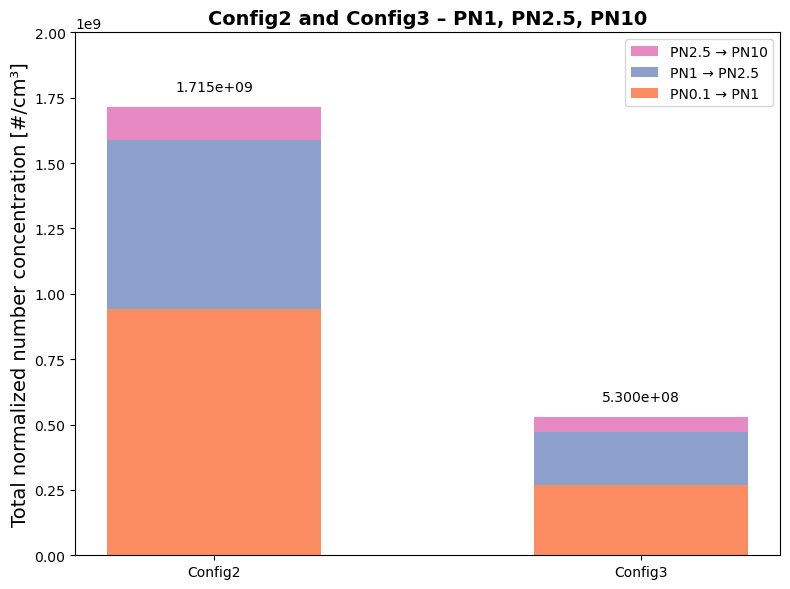

In [63]:
import matplotlib.pyplot as plt
import numpy as np

# Original data (indices: 0:Config1, 1:Config1-rep2, 2:Config2, 3:Config3, 4:Config4, 5:Config5, 6:Config6, 7:Config7)
seg_PM1   = [6.8e+08, 5.4e+08, 9.43e+08, (2.838e10 - 2.811e10), (7.116e10 - 7.024e10), (7.025e10 - 6.950e10), (3.889E10 - 3.841E10), (1.719E9 - 1.678E9)]
seg_PM2_5 = [2.9e+08, 2.4e+08, 6.45e+08, (2.858e10 - 2.838e10), (7.150e10 - 7.116e10), (7.064e10 - 7.025e10), (3.909E10 - 3.889E10), (1.738E9 - 1.719E9)]
seg_PM10  = [3.0e+07, 2.0e+07, 1.27e+08, (2.864e10 - 2.858e10), (7.153e10 - 7.150e10), (7.069e10 - 7.064e10), (3.911E10 - 3.909E10), (1.749E9 - 1.738E9)]

# Keep only Config2 (index 2) and Config3 (index 3)
indices = [2, 3]
categories = ['Config2', 'Config3']

seg_PM1   = [seg_PM1[i]   for i in indices]
seg_PM2_5 = [seg_PM2_5[i] for i in indices]
seg_PM10  = [seg_PM10[i]  for i in indices]

width = 0.5
x = np.arange(len(categories))

# Colors (without PM0.1)
colors = ['#fc8d62', '#8da0cb', '#e78ac3']  # PM1, PM2.5, PM10

fig, ax = plt.subplots(figsize=(8, 6))

# Stacked bars
bar_PM1   = ax.bar(x, seg_PM1, width, color=colors[0], label='PN0.1 → PN1')
bar_PM2_5 = ax.bar(x, seg_PM2_5, width, bottom=seg_PM1, color=colors[1], label='PN1 → PN2.5')
bar_PM10  = ax.bar(x, seg_PM10, width, bottom=np.array(seg_PM1)+np.array(seg_PM2_5), color=colors[2], label='PN2.5 → PN10')

# Totals (without PM0.1)
totaux = np.array(seg_PM1) + np.array(seg_PM2_5) + np.array(seg_PM10)
for i, total in enumerate(totaux):
    ax.text(x[i], total + 0.05e+9, f'{total:.3e}', ha='center', va='bottom', fontsize=10)

ax.set_title('Config2 and Config3 – PN1, PN2.5, PN10', fontsize=14)
ax.set_ylabel('Total normalized number concentration [#/cm³]')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylim(0, 2e9)  # still fine for these two (Config2 ~1.7e9, Config3 ~0.53e9)

# Legend in order PM10 → PM2.5 → PM1
handles, labels = ax.get_legend_handles_labels()
order = [2, 1, 0]  # PM10, PM2.5, PM1
ax.legend([handles[i] for i in order], [labels[i] for i in order])

plt.tight_layout()
plt.show()

In [62]:
# import matplotlib.pyplot as plt

# # Diamètres en micromètres (µm)
# diameters = {
#     "PM10": 10,
#     "PM2.5": 2.5,
#     "PM1": 1
# }

# # Conversion en rayons
# radii = {k: v / 2 for k, v in diameters.items()}

# # Création de la figure
# fig, ax = plt.subplots(figsize=(6, 6))

# # Couleurs (du plus grand au plus petit)
# colors = {
#     "PM10": "#cfeefa",
#     "PM2.5": "#8ecae6",
#     "PM1": "#5b8fd9"
# }

# # Ajout des cercles concentriques
# for label in ["PM10", "PM2.5", "PM1"]:
#     circle = plt.Circle(
#         (0, 0),
#         radii[label],
#         color=colors[label],
#         alpha=0.7,
#         label=label
#     )
#     ax.add_patch(circle)

# # Mise à l’échelle correcte
# ax.set_aspect("equal")
# ax.set_xlim(-5.5, 5.5)
# ax.set_ylim(-5.5, 5.5)

# # Suppression des axes
# ax.axis("off")

# # Légende
# ax.legend(loc="upper right")

# # Titre
# plt.title("Comparaison des diamètres des particules PM")

# plt.show()